# Bumper Beam and GeoTransolver: The Full Pipeline, From CAE Data to Animation

This notebook walks through the GeoTransolver one-shot crash surrogate in `examples/structural_mechanics/bumper_beam`, step by step, in the same order as **[BUMPER_BEAM_REPRODUCTION.md](../BUMPER_BEAM_REPRODUCTION.md)** (Part 1 to Part 9). It uses only open-source tools: **OpenRadioss** replaces LS-DYNA, so no commercial CAE license is needed.

```
DOE parameter table (generate_dataset.py)
   -> OpenRadioss solver (starter + engine)       -> ANIM / d3plot / T01 (one set per run)
   -> anim_to_vtk + vortex_radioss                -> d3plot (LS-DYNA compatible format)
   -> PhysicsNeMo-Curator ETL                     -> .vtp (one per run, displacement at each timestep)
   -> vtp_reader.Reader + CrashPointCloudDataset  -> SimSample (x, y, global_features)
   -> rollout.GeoTransolverOneShot                -> predicted trajectory [N, 50, Fo]
   -> inference.py + post_processing/             -> animations, error curves, VTU files
```

135 simulations (5 geometry scales x 3 impact velocities x 3 thickness scales x 1 wall diameter x 3 wall positions), split into 121 / 5 / 9 for train / val / test.

> **This notebook uses only real results. It does not generate demo data and does not train a demo model.** Every number, plot, and animation below comes from the 135 finished OpenRadioss simulations, the real Curator output, the real `train.py` runs (TensorBoard logs and checkpoints in `outputs/`), and the real trained checkpoints. The long-running steps (simulation, ETL, training) are shown as the commands that were used; the notebook then checks and visualizes what those commands produced.

## Part 1 — Environment Setup

| Item | Version / source |
|---|---|
| Windows | 10/11 with WSL2 |
| WSL distribution | Ubuntu 24.04 |
| OpenRadioss | Official build (GFortran Linux: `starter_linux64_gf`, `engine_linux64_gf`, `anim_to_vtk_linux64_gf`) |
| PhysicsNeMo | Local source checkout, **editable install** (not the `nvidia-physicsnemo` pip release) |
| PhysicsNeMo-Curator | Git tag **`PNM-25.11-Compatible`** (the main branch is no longer compatible) |
| Vortex-Radioss | Installed from GitHub source (not on PyPI) |
| GPU | CUDA GPU (verified with 8 GB VRAM) |

**Two Python environments.** OpenRadioss only ships Linux binaries, so it must run in WSL. Training uses CUDA, which is easiest in native Windows Python. So:
- **WSL venv** (`/opt/radioss_venv`): OpenRadioss batch runs and the PhysicsNeMo-Curator ETL (Part 2, Part 3).
- **Windows venv** (`.venv` at the PhysicsNeMo repo root): training, inference, and this notebook (Part 4 to Part 6).

**Known problems:**
- **Curator main branch**: the crash ETL was moved to `examples/cae/crashsim/` (argparse CLI, Zarr only, different fields). Use the tag `PNM-25.11-Compatible`, which still has `examples/structural_mechanics/crash/config/crash_etl.yaml`.
- **PhysicsNeMo pip release**: `pip install nvidia-physicsnemo` installs an older release whose `GeoTransolver` has no `activation_checkpointing` argument, so training fails with `TypeError`. Install the repo with `pip install -e . --no-deps`.

The cell below checks the Windows environment. It puts the repo root first on `sys.path` so `import physicsnemo` resolves to the local source, the same check as Part 1.4 of the guide.

In [1]:
import sys, os

# This project's root folder (contains train.py, rollout.py, conf/, this demo/ subfolder, ...).
PROJECT_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))

# Put the repo root first on sys.path so `import physicsnemo` resolves to the local
# source (editable install), not an older pip release. See Part 1.4 of the guide.
REPO_ROOT = os.path.abspath(os.path.join(PROJECT_DIR, "..", "..", ".."))
if os.path.basename(REPO_ROOT) != "physicsnemo":
    REPO_ROOT = r"C:\code\2-cae\physicsnemo"
sys.path.insert(0, REPO_ROOT)
sys.path.insert(0, PROJECT_DIR)  # so `import datapipe`, `import vtp_reader`, `import rollout` work
sys.path.insert(0, os.path.join(PROJECT_DIR, "post_processing"))

import torch
import physicsnemo
import physicsnemo.models.geotransolver.geotransolver as gt_module
import pyvista

print("physicsnemo source   :", physicsnemo.__file__)
print("GeoTransolver source :", gt_module.__file__)
assert "site-packages" not in gt_module.__file__, "physicsnemo resolves to a pip copy, not the local source"
print("torch:", torch.__version__, "| cuda available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("pyvista:", pyvista.__version__)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", DEVICE)

W1012 10:26:18.266000 10540 .venv\Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


physicsnemo source   : C:\code\2-cae\physicsnemo\physicsnemo\__init__.py
GeoTransolver source : C:\code\2-cae\physicsnemo\physicsnemo\models\geotransolver\geotransolver.py
torch: 2.14.0+cu130 | cuda available: True
GPU: NVIDIA GeForce RTX 4060 Ti
pyvista: 0.49.0
Using device: cuda


## Part 2 — Generate the CAE Dataset (OpenRadioss DOE)

The base model `Bumper_Beam_AP_meshed` is the official OpenRadioss example ([Bumper Beam wiki](https://openradioss.atlassian.net/wiki/spaces/OPENRADIOSS/pages/11075585/Bumper+Beam)). Its unit system is **kg-mm-ms**, so stress is in GPa and velocity is in mm/ms.

### 2.1 The engine deck

The engine deck `dataset_generation/templates/Bumper_Beam_AP_meshed_0001.rad` must use **`/ANIM/DT`**, not only `/H3D/DT`. `/H3D/DT` does not write the ASCII ANIM files (`*A001`, `*A002`, ...) that `anim_to_vtk` needs, and the rest of the pipeline breaks.

`TFREQ = 2.0` ms over a 100 ms run gives **51 output frames** (t = 0, 2, ..., 100 ms), which matches `num_time_steps: 51`. `/ANIM/SHELL/VONM` and `/ANIM/SHELL/EPSP` also write von Mises stress and plastic strain (used in Part 6).

The cell below prints the real engine deck and checks these settings.

In [2]:
ENGINE_DECK = os.path.join(PROJECT_DIR, "dataset_generation", "templates", "Bumper_Beam_AP_meshed_0001.rad")
deck = open(ENGINE_DECK).read()
print(deck)

for keyword in ["/ANIM/DT", "/ANIM/SHELL/VONM", "/ANIM/SHELL/EPSP"]:
    print(f"{keyword:<18} present: {keyword in deck}")

#
# Copyright (C) 2022 Altair Engineering Inc. ("Holder")
# Model is licensed by Holder under CC BY-NC 4.0
# (https://creativecommons.org/licenses/by-nc/4.0/legalcode).
/RUN/Bumper_Beam_AP_meshed/0/
                 100
/VERS/2022
/ANIM/DT
#   TSTART     TFREQ
0.000000 2.000000
/ANIM/SHELL/VONM
/ANIM/SHELL/EPSP
/DT/NODA/CST/0
0.9 0.001
/PRINT/-100/55
/TFILE/0
#            dT_HIS
0.100000

/ANIM/DT           present: True
/ANIM/SHELL/VONM   present: True
/ANIM/SHELL/EPSP   present: True


### 2.2 The DOE parameter table

`dataset_generation/generate_dataset.py` defines the DOE in `DEFAULT_EXPERIMENT_SETUP`:

| Parameter | Values | Count |
|---|---|---|
| Geometry scale (sx, sy, sz) | (1,1,1) (1,0.5,1) (1,1,0.5) (1,2,1) (1,1,2) | 5 |
| Impact velocity vx (mm/ms) | -5, -3, -7 | 3 |
| Thickness scale | 1.0, 0.7, 1.3 | 3 |
| Wall diameter (mm) | 254 | 1 |
| Wall position y (mm) | 0, 120, 240 | 3 |

5 x 3 x 3 x 1 x 3 = **135 runs**. The script writes `dataset/run1/` to `dataset/run135/`, each with a modified `_0000.rad`, a copy of `_0001.rad`, and `runN.json`, plus `dataset/summary.json` with all parameters.

```bash
cd "physicsnemo/examples/structural_mechanics/bumper_beam/dataset_generation"
source /opt/radioss_venv/bin/activate
python generate_dataset.py
```

In [3]:
import pandas as pd

sys.path.insert(0, os.path.join(PROJECT_DIR, "dataset_generation"))
from generate_dataset import DEFAULT_EXPERIMENT_SETUP

setup = DEFAULT_EXPERIMENT_SETUP
n_combos = (len(setup["geometry_scales"]) * len(setup["velocities"])
            * len(setup["thickness_scales"]) * len(setup["rwall_diameters"])
            * len(setup["rwall_origins"]))
print("DOE variables:")
for k, v in setup.items():
    print(f"  {k}: {v}")
print("Total combinations =", n_combos)

# The real parameter record written by generate_dataset.py
summary = pd.read_csv(os.path.join(PROJECT_DIR, "dataset_generation", "dataset", "summary.csv"))
print(f"\nsummary.csv: {len(summary)} runs")
summary.drop(columns=["Timestamp"]).head(6)

DOE variables:
  geometry_scales: [(1.0, 1.0, 1.0), (1.0, 0.5, 1.0), (1.0, 1.0, 0.5), (1.0, 2.0, 1.0), (1.0, 1.0, 2.0)]
  velocities: [(-5.0, 0.0, 0.0), (-3.0, 0.0, 0.0), (-7.0, 0.0, 0.0)]
  thickness_scales: [1.0, 0.7, 1.3]
  rwall_diameters: [254.0]
  rwall_origins: [(-170.0, 0.0, 0.0), (-170.0, 120.0, 0.0), (-170.0, 240.0, 0.0)]
Total combinations = 135

summary.csv: 135 runs


,Run_ID,Geo_Scale_X,Geo_Scale_Y,Geo_Scale_Z,Vel_X,Vel_Y,Vel_Z,Thickness_Factor,Wall_Diameter,Wall_X,Wall_Y,Wall_Z
0,run1,1.0,1.0,1.0,-5.0,0.0,0.0,1.0,254.0,-170.0,0.0,0.0
1,run2,1.0,1.0,1.0,-5.0,0.0,0.0,1.0,254.0,-170.0,120.0,0.0
2,run3,1.0,1.0,1.0,-5.0,0.0,0.0,1.0,254.0,-170.0,240.0,0.0
3,run4,1.0,1.0,1.0,-5.0,0.0,0.0,0.7,254.0,-170.0,0.0,0.0
4,run5,1.0,1.0,1.0,-5.0,0.0,0.0,0.7,254.0,-170.0,120.0,0.0
5,run6,1.0,1.0,1.0,-5.0,0.0,0.0,0.7,254.0,-170.0,240.0,0.0


### 2.3 Batch simulation

```bash
export OPENRADIOSS_ROOT=/mnt/c/code/2-cae/OpenRadioss
export MAX_PARALLEL_JOBS=5
export OMP_NUM_THREADS=2
python run_simulations.py
```

Each run goes through `starter` -> `engine`, then two **independent** conversions of the ANIM frames (`common/radioss_runner.py` runs them one after the other, but neither one uses the other's output):

```
starter -> engine -> ANIM (A001 ... A051) -+- vortex_radioss.Anim_to_D3plot -> d3plot  -> Curator -> .vtp -> training (position)
                                           +- anim_to_vtk                    -> .vtk    -> Part 6: stress / plastic strain
                                                                                        -> quick check in ParaView
```

- **d3plot** is the only input Curator reads (Part 3). `readAndConvert()` reads the ANIM files directly, not the `.vtk` files.
- **`.vtk`** keeps the von Mises stress and plastic strain (`/ANIM/SHELL/VONM`, `/ANIM/SHELL/EPSP`) that `vortex_radioss` drops, so Part 6 needs it. ANIM is a Radioss-only format, so the `.vtk` files are also the easiest way to look at a run in ParaView before the ETL. A position-only model does not need them.

- **Why 5 jobs x 2 threads (on this machine)**: the batch ran on an **Intel Core i5-13400F**: 10 physical cores (6 P-cores with Hyper-Threading + 4 E-cores without it), 16 logical threads, all 16 visible in WSL (`nproc`).
  - **Count physical cores, not logical threads.** The engine is floating-point bound; two Hyper-Threads on one core share its FP units and cache, so they add almost nothing. Aim for `MAX_PARALLEL_JOBS x OMP_NUM_THREADS ~ physical cores` (5 x 2 = 10).
  - **Many small jobs instead of one big one.** The runs are independent, so running them side by side scales almost perfectly. OpenMP inside one run does not: this model has only ~13,700 nodes, so with 10 threads the synchronization overhead would likely take a large share. 5 x 2 is the measured compromise; 10 x 1 was not tested.
  - **The machine is saturated at 5 jobs.** 5-way and 6-way parallel runs had almost the same throughput (~0.0038 runs/s), so more jobs do not help. The limit is probably memory bandwidth, the slower E-cores, and the WSL file system, not the thread count.
  - `run_simulations.py` defaults to `MAX_PARALLEL_JOBS=2`, `OMP_NUM_THREADS=8`, which is why the two `export` lines above override them. On another machine, start with `MAX_PARALLEL_JOBS = physical cores / OMP_NUM_THREADS` and compare the throughput with one job more and one job less.
- **Run time**: one run **alone** takes about **450 s** with 2 threads. With **5 runs in parallel** each one slows down to about **1,200 to 1,300 s** (engine `ELAPSED TIME` in the `.out` files of all 135 runs: 1,116 to 1,298 s, median 1,209 s), most likely because the jobs compete for memory bandwidth. The total throughput is ~0.0038 runs/s, so all 135 runs take about **8 to 10 hours**.
- **Restart after an interruption**: WSL2 does not resume after a Windows reboot. Move finished runs (`NORMAL TERMINATION` in `engine.log` plus a d3plot) to a backup folder, reset the unfinished ones to their 3 input files, and start `run_simulations.py` again. See Part 2.3 of the guide for the script.
- **Never start two batches on the same folders**: two processes pick the same first runs and overwrite each other's files. Check with `ps aux | grep run_simulations.py`.

The cell below checks the real simulation output of all 135 runs.

In [4]:
import glob
import re

SIM_DIR = os.path.join(PROJECT_DIR, "dataset_generation", "dataset")
run_dirs = sorted(glob.glob(os.path.join(SIM_DIR, "run*")), key=lambda d: int(os.path.basename(d)[3:]))
run_dirs = [d for d in run_dirs if os.path.isdir(d)]

rows = []
for d in run_dirs:
    log = os.path.join(d, "engine.log")
    normal = os.path.exists(log) and "NORMAL TERMINATION" in open(log, errors="ignore").read()
    rows.append({
        "run": os.path.basename(d),
        "normal_termination": normal,
        "anim_frames": len(glob.glob(os.path.join(d, "Bumper_Beam_AP_meshedA[0-9][0-9][0-9]"))),
        "vtk_frames": len(glob.glob(os.path.join(d, "Bumper_Beam_AP_meshedA[0-9][0-9][0-9].vtk"))),
        "d3plot": os.path.exists(os.path.join(d, "d3plot")),
        "d3plot_files": len(glob.glob(os.path.join(d, "d3plot"))) + len(glob.glob(os.path.join(d, "d3plot[0-9][0-9]"))),
    })
sim_status = pd.DataFrame(rows)

print("run folders              :", len(sim_status))
print("NORMAL TERMINATION       :", sim_status.normal_termination.sum())
print("runs with 51 ANIM frames :", (sim_status.anim_frames == 51).sum())
print("runs with 51 .vtk frames :", (sim_status.vtk_frames == 51).sum())
print("runs with d3plot         :", sim_status.d3plot.sum())
ok = (sim_status.normal_termination & (sim_status.anim_frames == 51)
      & (sim_status.vtk_frames == 51) & sim_status.d3plot)
print("incomplete runs          :", "none" if ok.all() else list(sim_status.run[~ok]))
print("d3plot files per run     :", dict(sim_status.d3plot_files.value_counts()), " (d3plot + d3plot01 ... d3plot51)")

# One row per run; the first and last 5 of the 135 rows
with pd.option_context("display.max_rows", 10):
    display(sim_status)

run folders              : 135
NORMAL TERMINATION       : 135
runs with 51 ANIM frames : 135
runs with 51 .vtk frames : 135
runs with d3plot         : 135
incomplete runs          : none
d3plot files per run     : {52: np.int64(135)}  (d3plot + d3plot01 ... d3plot51)


,run,normal_termination,anim_frames,vtk_frames,d3plot,d3plot_files
0,run1,True,51,51,True,52
1,run2,True,51,51,True,52
2,run3,True,51,51,True,52
3,run4,True,51,51,True,52
4,run5,True,51,51,True,52
...,...,...,...,...,...,...
130,run131,True,51,51,True,52
131,run132,True,51,51,True,52
132,run133,True,51,51,True,52
133,run134,True,51,51,True,52


### 2.4 Export the ground truth to VTU (for ParaView)

> **Order note**: this step is shown here, right after the simulations, so you can look at the runs early. But `export_vtu.py` reads the Curator `.vtp` files in `data_full/vtk/{train,val,test}/`, so on a new setup run it **after Part 3 (ETL) and 3.1 (split)**.

Each Curator `.vtp` keeps the whole trajectory in one file. `post_processing/export_vtu.py` splits every run into one `.vtu` per timestep, with the mesh moved to its deformed position, and writes a `.pvd` file so ParaView opens the run as a time series:

```
data_full/compare_vtu/openradioss/
  train/ val/ test/
    runN/
      runN.pvd                           <- open this in ParaView
      vtu/runN_000.vtu ... runN_050.vtu  (51 frames, t = 0 to 0.100 s)
```

Fields: point data `displacement` (vector, relative to t0) and `thickness`; cell data `stress_vm` and `effective_plastic_strain` (added in Part 6). All 135 runs take about 45 seconds and about 4.2 GB. Runs that are already exported are skipped; use `--overwrite` to redo them or `--runs run1,run91` to export only some runs.

In [8]:
import subprocess

VTU_ROOT = os.path.join(PROJECT_DIR, "data_full", "compare_vtu")
GT_VTU_ROOT = os.path.join(VTU_ROOT, "openradioss")

# Runs that already have a .pvd file are skipped
result = subprocess.run([sys.executable, os.path.join(PROJECT_DIR, "post_processing", "export_vtu.py")],
                        capture_output=True, text=True)
print("\n".join(result.stdout.strip().splitlines()[-1:]))
if result.returncode != 0:
    print(result.stderr)

for split in ["train", "val", "test"]:
    n = len(glob.glob(os.path.join(GT_VTU_ROOT, split, "run*", "*.pvd")))
    print(f"  openradioss/{split:<5}: {n} runs")
sample_vtu = pyvista.read(os.path.join(GT_VTU_ROOT, "train", "run1", "vtu", "run1_050.vtu"))
print("run1_050.vtu:", sample_vtu.n_points, "points,", sample_vtu.n_cells, "cells")
print("  point data:", list(sample_vtu.point_data.keys()))
print("  cell data :", list(sample_vtu.cell_data.keys()))

Done: 135 succeeded, 0 failed
  openradioss/train: 121 runs
  openradioss/val  : 5 runs
  openradioss/test : 9 runs
run1_050.vtu: 13675 points, 13626 cells
  point data: ['displacement', 'thickness']
  cell data : ['stress_vm', 'effective_plastic_strain']


#### Example runs: one DOE variable at a time

To see what each DOE variable does, start from the **baseline run** of the DOE in Part 2.2 (geometry (1, 1, 1), vx = -5 mm/ms, thickness 1.0, wall y = 0) and change **one variable at a time**. That gives 11 cases in three groups:

| Group | Cases | Variable changed | Values |
|---|---|---|---|
| geometry | G1 to G5 | `geometry_scales` | (1,1,1) (1,0.5,1) (1,1,0.5) (1,2,1) (1,1,2) |
| thickness | T1 to T3 | `thickness_scales` | 1.0 0.7 1.3 |
| wall | W1 to W3 | `rwall_origins` (y) | 0 120 240 |

G1, T1, and W1 are the same baseline run (`run1`), so the 11 cases use 9 different runs. The cases are looked up in `summary.csv`, and each table below shows the real parameter row of every case next to its animation.

`post_processing/make_doe_examples.py` renders one GIF per group (ground truth only, 0 to 100 ms, every second frame). Each panel shows the deformed beam colored by displacement magnitude, with the rigid wall drawn as a gray cylinder (`/RWALL/CYL`: axis along z, diameter 254 mm). The x/y/z triad in the lower left corner of each panel gives the directions: the impact is along -x, the beam's long axis is y. The panels in a group share one view scale and one color range. **The color range is different for each group**, so `run1` looks different in G1, T1, and W1.

> These animations read the ground-truth VTU files exported in the cell above. The DOE itself is described in Part 2.2.


=== geometry: G1, G2, G3, G4, G5 ===


,Run_ID,Geo_Scale_X,Geo_Scale_Y,Geo_Scale_Z,Vel_X,Vel_Y,Vel_Z,Thickness_Factor,Wall_Diameter,Wall_X,Wall_Y,Wall_Z
Case,,,,,,,,,,,,
G1,run1,1.0,1.0,1.0,-5.0,0.0,0.0,1.0,254.0,-170.0,0.0,0.0
G2,run28,1.0,0.5,1.0,-5.0,0.0,0.0,1.0,254.0,-170.0,0.0,0.0
G3,run55,1.0,1.0,0.5,-5.0,0.0,0.0,1.0,254.0,-170.0,0.0,0.0
G4,run82,1.0,2.0,1.0,-5.0,0.0,0.0,1.0,254.0,-170.0,0.0,0.0
G5,run109,1.0,1.0,2.0,-5.0,0.0,0.0,1.0,254.0,-170.0,0.0,0.0


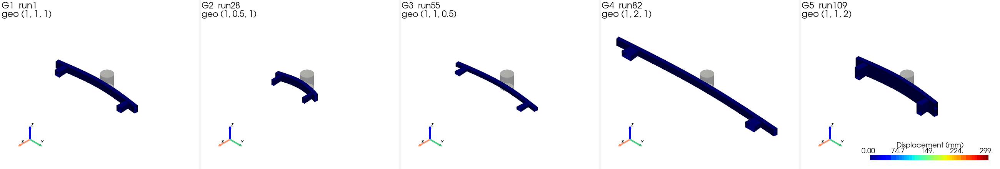


=== thickness: T1, T2, T3 ===


,Run_ID,Geo_Scale_X,Geo_Scale_Y,Geo_Scale_Z,Vel_X,Vel_Y,Vel_Z,Thickness_Factor,Wall_Diameter,Wall_X,Wall_Y,Wall_Z
Case,,,,,,,,,,,,
T1,run1,1.0,1.0,1.0,-5.0,0.0,0.0,1.0,254.0,-170.0,0.0,0.0
T2,run4,1.0,1.0,1.0,-5.0,0.0,0.0,0.7,254.0,-170.0,0.0,0.0
T3,run7,1.0,1.0,1.0,-5.0,0.0,0.0,1.3,254.0,-170.0,0.0,0.0


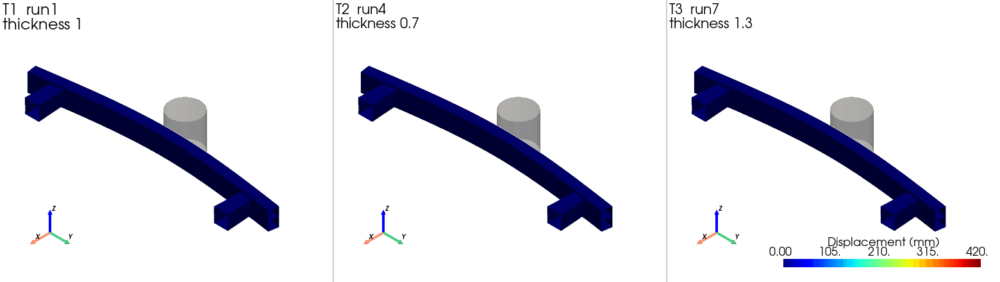


=== wall: W1, W2, W3 ===


,Run_ID,Geo_Scale_X,Geo_Scale_Y,Geo_Scale_Z,Vel_X,Vel_Y,Vel_Z,Thickness_Factor,Wall_Diameter,Wall_X,Wall_Y,Wall_Z
Case,,,,,,,,,,,,
W1,run1,1.0,1.0,1.0,-5.0,0.0,0.0,1.0,254.0,-170.0,0.0,0.0
W2,run2,1.0,1.0,1.0,-5.0,0.0,0.0,1.0,254.0,-170.0,120.0,0.0
W3,run3,1.0,1.0,1.0,-5.0,0.0,0.0,1.0,254.0,-170.0,240.0,0.0


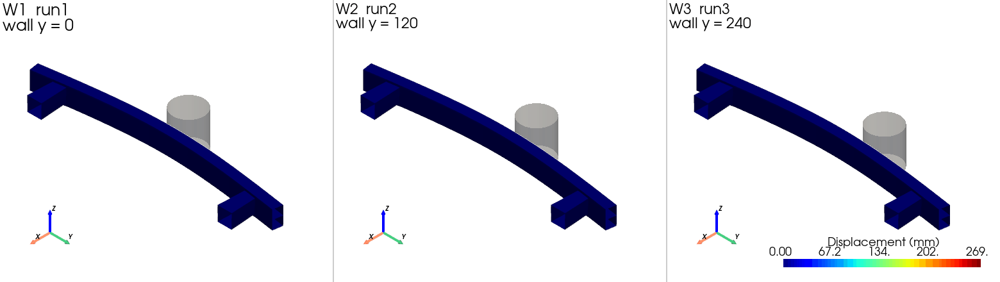

In [25]:
from make_doe_examples import select_cases, make_group_gif, GIF_DIR, GIF_ZOOM, PARAM_COLS
from IPython.display import Image, display

doe_cases = select_cases()
os.makedirs(GIF_DIR, exist_ok=True)
for group in ["geometry", "thickness", "wall"]:
    gif = os.path.join(GIF_DIR, f"doe_{group}.gif")
    if not os.path.exists(gif):  # delete the GIF to render it again
        make_group_gif(doe_cases[doe_cases.Group == group], gif, zoom=GIF_ZOOM[group])
    rows = doe_cases[doe_cases.Group == group]
    print(f"\n=== {group}: {', '.join(rows.Case)} ===")
    display(rows[["Case"] + PARAM_COLS].set_index("Case"))
    display(Image(filename=gif))

#### Open the 11 cases in ParaView

Each run already has its own time series from the export above, `data_full/compare_vtu/openradioss/<split>/runN/runN.pvd` (one `.vtu` per frame in `vtu/`). The column `GT_PVD` below gives the path for each case.

To compare the cases side by side, `make_doe_examples.py` also writes **one combined `.pvd`** with all 11 cases in one scene:

```
data_full/compare_vtu/doe_11cases/
  doe_11cases.pvd                    <- open this in ParaView
  cases.csv                          case -> run, DOE parameters, tile offset
  vtu/G1_run1_000.vtu ... W3_run3_050.vtu    (11 cases x 51 frames, beam)
  vtu/G1_wall.vtu ... W3_wall.vtu            (rigid wall of each case)
```

- **Layout**: each group is one row along +y (geometry, thickness, wall, 4600 mm apart), and each case one column along +x (900 mm apart). The beam and its wall are moved together by `(Offset_X, Offset_Y)`, so the wall position relative to the beam is unchanged.
- **Parts**: parts 0 to 10 are the beams (in the order of the table), parts 11 to 21 are the walls. In ParaView they become the blocks of one multiblock dataset.
- **Fields**: the same as the per-run VTU files (point data `displacement`, `thickness`; cell data `stress_vm`, `effective_plastic_strain`), plus cell data `case_index` (0 to 10).
- The beam files are copies with moved coordinates (about 350 MB in total). Existing files are skipped; use `python post_processing/make_doe_examples.py --overwrite` to write them again.

In ParaView: **File → Open** `doe_11cases.pvd` → **Apply** → color by `displacement` (Magnitude) → press **Play**. Use the **Multiblock Inspector** to hide the walls or set their opacity. Use the view **-Z** (looking down) to see the wall offsets clearly.

In [26]:
from make_doe_examples import write_combined_pvd

doe_pvd = write_combined_pvd(doe_cases)  # Existing files are skipped
print("\nOpen in ParaView:", doe_pvd)

show = doe_cases[["Case", "Run_ID", "Varied", "Split", "GT_PVD", "Offset_X", "Offset_Y"]].copy()
show["GT_PVD"] = show.GT_PVD.map(lambda p: os.path.relpath(p, PROJECT_DIR))
show.set_index("Case")

Saved C:\code\2-cae\physicsnemo\examples\structural_mechanics\bumper_beam\data_full\compare_vtu\doe_11cases\doe_11cases.pvd (11 cases x 51 frames, beams = parts 0-10, walls = parts 11-21)

Open in ParaView: C:\code\2-cae\physicsnemo\examples\structural_mechanics\bumper_beam\data_full\compare_vtu\doe_11cases\doe_11cases.pvd


,Run_ID,Varied,Split,GT_PVD,Offset_X,Offset_Y
Case,,,,,,
G1,run1,"geo (1, 1, 1)",train,data_full\compare_vtu\openradioss\train\run1\r...,0.0,0.0
G2,run28,"geo (1, 0.5, 1)",train,data_full\compare_vtu\openradioss\train\run28\...,900.0,0.0
G3,run55,"geo (1, 1, 0.5)",train,data_full\compare_vtu\openradioss\train\run55\...,1800.0,0.0
G4,run82,"geo (1, 2, 1)",train,data_full\compare_vtu\openradioss\train\run82\...,2700.0,0.0
G5,run109,"geo (1, 1, 2)",train,data_full\compare_vtu\openradioss\train\run109...,3600.0,0.0
T1,run1,thickness 1,train,data_full\compare_vtu\openradioss\train\run1\r...,0.0,4600.0
T2,run4,thickness 0.7,train,data_full\compare_vtu\openradioss\train\run4\r...,900.0,4600.0
T3,run7,thickness 1.3,train,data_full\compare_vtu\openradioss\train\run7\r...,1800.0,4600.0
W1,run1,wall y = 0,train,data_full\compare_vtu\openradioss\train\run1\r...,0.0,9200.0


### 2.5 Prepare the files for Curator

```bash
# Rename <BASE>.d3plot* to d3plot, d3plot01, ...
python common/rename_d3plot.py --dataset-dir ./dataset --base-name Bumper_Beam_AP_meshed

# summary.json -> global_features.json (per-run global parameters for training)
python restructure_global_features.py --input ./dataset/summary.json --output ./global_features.json
```

The cell below loads the real `global_features.json` and counts how many runs have each value. Each DOE level should appear in the same number of runs.

In [5]:
import json
from collections import Counter

GLOBAL_FEATURES_PATH = os.path.join(PROJECT_DIR, "dataset_generation", "global_features.json")
assert os.path.exists(GLOBAL_FEATURES_PATH), (
    f"{GLOBAL_FEATURES_PATH} not found, run restructure_global_features.py first"
)
with open(GLOBAL_FEATURES_PATH, encoding="utf-8") as f:
    gf = json.load(f)

print(f"global_features.json has global parameters for {len(gf)} runs")
print("run1 =", gf["run1"])
print()
for key in ["velocity_x", "thickness_scale", "rwall_origin_y", "geo_scale_y", "geo_scale_z"]:
    print(f"{key:<16}", dict(sorted(Counter(v[key] for v in gf.values()).items())))

global_features.json has global parameters for 135 runs
run1 = {'geo_scale_x': 1.0, 'geo_scale_y': 1.0, 'geo_scale_z': 1.0, 'velocity_x': -5.0, 'velocity_y': 0.0, 'velocity_z': 0.0, 'thickness_scale': 1.0, 'rwall_diameter': 254.0, 'rwall_origin_x': -170.0, 'rwall_origin_y': 0.0, 'rwall_origin_z': 0.0}

velocity_x       {-7.0: 45, -5.0: 45, -3.0: 45}
thickness_scale  {0.7: 45, 1.0: 45, 1.3: 45}
rwall_origin_y   {0.0: 45, 120.0: 45, 240.0: 45}
geo_scale_y      {0.5: 27, 1.0: 81, 2.0: 27}
geo_scale_z      {0.5: 27, 1.0: 81, 2.0: 27}


#### What goes to Curator

Curator does not need a file list or a manifest. Its data source (`CrashD3PlotDataSource` in `physicsnemo-curator/examples/structural_mechanics/crash/data_sources.py`) works on folders:

1. **Find the runs**: every sub-folder of `etl.source.input_dir` that has a file named exactly **`d3plot`** is one run. The folder name becomes the run ID and the output file name (`run1/` -> `run1.vtp`). This is why 2.5 renames `Bumper_Beam_AP_meshed.d3plot*` to `d3plot, d3plot01, ...`: with the original names Curator finds 0 runs and gives no error.
2. **Read the run**: `lasso.dyna.D3plot("run1/d3plot")` opens the header file `d3plot` and its continuation files `d3plot01 ... d3plot51` together. Curator takes only 4 arrays from it. For `run1` (read with `lasso` in the WSL venv; it is not installed in the Windows venv):

   | Array | Shape | Meaning |
   |---|---|---|
   | `node_coordinates` | `(13882, 3)` | t0 node positions |
   | `node_displacement` | `(51, 13882, 3)` | node positions at all 51 frames |
   | `element_shell_node_indexes` | `(13626, 4)` | shell mesh (quads; triangles repeat a node) |
   | `element_shell_part_indexes` | `(13626,)` | part of each shell |

3. **Thickness (optional)**: the first `*.k` file in the run folder, if there is one. OpenRadioss has none, so the per-node thickness is 0 (see Part 3).
4. **Clean up**: nodes that move less than `wall_threshold` (1.0 mm) over the whole run are treated as rigid wall nodes and removed; the mesh is renumbered. For `run1` this removes 207 nodes: 13882 -> **13675**, the node count used everywhere after this.
5. **Write**: one `.vtp` per run with the t0 mesh and `displacement_t0.000 ... displacement_t0.100`.

Everything else in the run folder (ANIM, `.vtk`, `.rst`, `.out`, logs, `runN.json`) is ignored. The DOE parameters do **not** go through Curator: they reach the training through `global_features.json` (2.5), matched to each `.vtp` by run ID.

The cell below sorts the files of one real run folder by who reads them.

In [27]:
RUN = "run1"
run_dir = os.path.join(SIM_DIR, RUN)

def used_by(name):
    if name == "d3plot" or re.fullmatch(r"d3plot\d+", name):
        return "Curator (Part 3)"
    if name.endswith(".k"):
        return "Curator, thickness (none here)"
    if re.fullmatch(r".*A\d{3}\.vtk", name):
        return "Part 6 + ParaView"
    if re.fullmatch(r".*A\d{3}", name):
        return "converters only (-> d3plot, -> .vtk)"
    if name.endswith(".json"):
        return "summary.json -> global_features.json (2.5)"
    if name.endswith("_0000.rad") or name.endswith("_0001.rad"):
        return "solver input"
    return "not used later (restart / logs)"

files = []
for name in sorted(os.listdir(run_dir)):
    path = os.path.join(run_dir, name)
    if os.path.isfile(path):
        files.append({"used_by": used_by(name), "file": name, "MB": os.path.getsize(path) / 1e6})
files = pd.DataFrame(files)

summary_by_use = (files.groupby("used_by")
                  .agg(n_files=("file", "size"), MB=("MB", "sum"),
                       example=("file", lambda s: s.iloc[0] if len(s) == 1 else f"{s.iloc[0]} ... {s.iloc[-1]}"))
                  .sort_values("MB", ascending=False).round(1))
print(f"{RUN}/: {len(files)} files, {files.MB.sum():.0f} MB")
display(summary_by_use)


run1/: 166 files, 197 MB


,n_files,MB,example
used_by,,,
not used later (restart / logs),9,57.4,Bumper_Beam_AP_meshedT01 ... starter.log
Part 6 + ParaView,51,55.3,Bumper_Beam_AP_meshedA001.vtk ... Bumper_Beam_...
Curator (Part 3),52,46.5,d3plot ... d3plot51
"converters only (-> d3plot, -> .vtk)",51,36.2,Bumper_Beam_AP_meshedA001 ... Bumper_Beam_AP_m...
solver input,2,1.8,Bumper_Beam_AP_meshed_0000.rad ... Bumper_Beam...
summary.json -> global_features.json (2.5),1,0.0,run1.json


## Part 3 — Curator ETL: d3plot to VTP

```bash
cd /opt/physicsnemo-curator/examples/structural_mechanics/crash
source /opt/radioss_venv/bin/activate
python run_etl.py --config-name=crash_etl \
    serialization_format=vtp \
    etl.source.input_dir=/path/to/bumper_beam/dataset_generation/dataset \
    serialization_format.sink.output_dir=/path/to/bumper_full_vtp \
    serialization_format.sink.time_step=0.002 \
    etl.processing.num_processes=4
```

- `serialization_format.sink.time_step=0.002` matches the 2 ms ANIM interval, so the labels `displacement_t0.000, displacement_t0.002, ...` are the real physical times. Curator does not read the simulation time; a wrong value only gives wrong labels, with no error.
- All 135 runs convert in about **44 seconds**.
- **The warning about a missing `.k` file is normal.** Curator tries to read the per-node shell thickness from an LS-DYNA `.k` file. OpenRadioss uses `.rad` files, so there is no `.k` file and the per-node `thickness` field falls back to 0. This does not lose the thickness information: the 3 thickness levels (0.7 / 1.0 / 1.3) go into the model as the global feature `thickness_scale` (Part 2.5). The per-node field is not used (`static_features: []`).

The cell below follows one run through the ETL. It prints the source files, then opens the `.vtp` and shows what is inside:

| | Path | |
|---|---|---|
| Input (Curator reads) | `dataset_generation/dataset/run1/d3plot`, `d3plot01 ... d3plot51` | 52 files |
| Curator output (WSL) | `/tmp/bumper_full_vtp/run1.vtp` | `serialization_format.sink.output_dir` |
| Used for training | `data_full/vtk/train/run1.vtp` | copied there by the 3.1 split |

The file in `data_full/vtk/` also has the `cell_stress_vm_t*` / `cell_effective_plastic_strain_t*` arrays. Curator does not write these; Part 6 adds them later. Plain Curator output has only `thickness` and `displacement_t*`.

In [6]:
import numpy as np

DATA_ROOT = os.path.join(PROJECT_DIR, "data_full", "vtk")  # Real Curator output, already split into train/val/test
RUN = "run1"

# --- Source files --------------------------------------------------------------
d3plot_dir = os.path.join(PROJECT_DIR, "dataset_generation", "dataset", RUN)
d3plot_files = sorted(f for f in os.listdir(d3plot_dir) if f == "d3plot" or re.fullmatch(r"d3plot\d+", f))
vtp_path = os.path.join(DATA_ROOT, "train", f"{RUN}.vtp")
print("Input  (d3plot) :", os.path.join(d3plot_dir, d3plot_files[0]),
      f"... {d3plot_files[-1]}  ({len(d3plot_files)} files, "
      f"{sum(os.path.getsize(os.path.join(d3plot_dir, f)) for f in d3plot_files) / 1e6:.1f} MB)")
print("Curator output  : /tmp/bumper_full_vtp/run1.vtp  (WSL)")
print("Output (.vtp)   :", vtp_path, f"({os.path.getsize(vtp_path) / 1e6:.1f} MB)")

# --- What is inside --------------------------------------------------------------
vtp = pyvista.read(vtp_path)
print()
print(vtp)

disp_keys = sorted(k for k in vtp.point_data.keys() if k.startswith("displacement_t"))
cell_keys = list(vtp.cell_data.keys())
print(f"point data: {len(vtp.point_data.keys())} arrays = thickness + {len(disp_keys)} x displacement_t* "
      f"({disp_keys[0]} ... {disp_keys[-1]}), each {vtp[disp_keys[-1]].shape}")
print(f"cell data : {len(cell_keys)} arrays ({cell_keys[0]} ... {cell_keys[-1]}), added in Part 6, not by Curator")
print("max |displacement| at t=0.100 s (mm):", np.linalg.norm(vtp[disp_keys[-1]], axis=1).max().round(1))
print("per-node thickness (no .k file, falls back to 0): min =", vtp["thickness"].min(), " max =", vtp["thickness"].max())

# First nodes: t0 coordinates and displacement at three times
print("\nFirst 5 nodes (mm):")
nodes = pd.DataFrame(vtp.points[:5], columns=["x", "y", "z"]).round(2)
for key in ["displacement_t0.000", "displacement_t0.050", "displacement_t0.100"]:
    nodes[key.replace("displacement_", "u_")] = [tuple(np.round(v, 1)) for v in vtp[key][:5]]
display(nodes)

# First cells: shell connectivity (node indices)
faces = vtp.faces.reshape(-1, 5)  # [4, n0, n1, n2, n3] for every quad
print("First 3 shell cells (node indices):", faces[:3, 1:].tolist())

Input  (d3plot) : C:\code\2-cae\physicsnemo\examples\structural_mechanics\bumper_beam\dataset_generation\dataset\run1\d3plot ... d3plot51  (52 files, 46.5 MB)
Curator output  : /tmp/bumper_full_vtp/run1.vtp  (WSL)
Output (.vtp)   : C:\code\2-cae\physicsnemo\examples\structural_mechanics\bumper_beam\data_full\vtk\train\run1.vtp (14.8 MB)



PolyData (0x29f4c19a560)
  N Cells:    13626
  N Points:   13675
  N Strips:   0
  X Bounds:   -4.000e+01, 3.176e+02
  Y Bounds:   -1.012e+03, 1.012e+03
  Z Bounds:   -7.500e+01, 7.500e+01
  N Arrays:   154
point data: 52 arrays = thickness + 51 x displacement_t* (displacement_t0.000 ... displacement_t0.100), each (13675, 3)
cell data : 102 arrays (cell_stress_vm_t0.000 ... cell_effective_plastic_strain_t0.100), added in Part 6, not by Curator
max |displacement| at t=0.100 s (mm): 264.3
per-node thickness (no .k file, falls back to 0): min = 0.0  max = 0.0

First 5 nodes (mm):


,x,y,z,u_t0.000,u_t0.050,u_t0.100
0,-40.00,-0.00,75.0,"(0.0, 0.0, 0.0)","(23.0, -0.1, -1.6)","(27.2, -0.1, -2.1)"
1,-39.98,-9.98,75.0,"(0.0, 0.0, 0.0)","(17.8, 4.4, -2.1)","(21.6, 4.8, -2.6)"
2,-39.93,-19.96,75.0,"(0.0, 0.0, 0.0)","(8.8, 12.4, -3.1)","(12.3, 14.4, -3.7)"
3,-39.85,-29.94,75.0,"(0.0, 0.0, 0.0)","(0.4, 16.5, -2.8)","(3.1, 19.9, -3.6)"
4,-39.74,-39.91,75.0,"(0.0, 0.0, 0.0)","(-4.6, 17.3, -2.6)","(-2.8, 21.2, -3.3)"


First 3 shell cells (node indices): [[305, 307, 309, 304], [304, 309, 300, 301], [307, 308, 310, 309]]


### 3.1 Split into train / val / test

The Curator `.vtp` files go to `data_full/vtk/` (`data_full/compare_vtu/` holds the VTU files for ParaView, see 2.4, 5.2 and 5.3):

```bash
mkdir -p data_full/vtk/train data_full/vtk/val data_full/vtk/test
i=0
for f in $(ls /path/to/bumper_full_vtp/*.vtp | sort); do
  i=$((i+1))
  if [ "$i" -le 121 ]; then cp "$f" data_full/vtk/train/
  elif [ "$i" -le 126 ]; then cp "$f" data_full/vtk/val/
  else cp "$f" data_full/vtk/test/
  fi
done
```

`ls | sort` is a text sort (`run1, run10, run100, ...`), so the test set is `run91` to `run99`.

In [7]:
NUM_STEPS = 51                       # /ANIM/DT TFREQ=2ms over a 100ms run -> 51 frames (see Part 2.1)
n_train, n_val, n_test = 121, 5, 9   # Matches the real split in bumper_openradioss_oneshot.yaml

print("DATA_ROOT =", DATA_ROOT)
split_runs = {}
for split, n_expect in [("train", n_train), ("val", n_val), ("test", n_test)]:
    files = sorted(glob.glob(os.path.join(DATA_ROOT, split, "*.vtp")))
    split_runs[split] = [os.path.splitext(os.path.basename(f))[0] for f in files]
    status = "OK" if len(files) == n_expect else "!! Count mismatch, check that the data is in place !!"
    print(f"  {split:<6} {len(files):>4} .vtp files   {status}")
print("val runs :", split_runs["val"])
print("test runs:", split_runs["test"])

DATA_ROOT = C:\code\2-cae\physicsnemo\examples\structural_mechanics\bumper_beam\data_full\vtk
  train   121 .vtp files   OK
  val       5 .vtp files   OK
  test      9 .vtp files   OK
val runs : ['run87', 'run88', 'run89', 'run9', 'run90']
test runs: ['run91', 'run92', 'run93', 'run94', 'run95', 'run96', 'run97', 'run98', 'run99']


## Part 4 — Training

### 4.1 Experiment config and data shapes

The experiment config is `conf/bumper_openradioss_oneshot.yaml`. The cell below loads it with Hydra, the same way `train.py` does, and prints the settings that define the problem.

In [9]:
from hydra import compose, initialize_config_dir
from omegaconf import OmegaConf

with initialize_config_dir(config_dir=os.path.join(PROJECT_DIR, "conf"), version_base="1.3"):
    cfg = compose(
        config_name="bumper_openradioss_oneshot",
        overrides=[
            f"training.raw_data_dir={os.path.join(DATA_ROOT, 'train')}",
            f"training.raw_data_dir_validation={os.path.join(DATA_ROOT, 'val')}",
            f"training.global_features_filepath={GLOBAL_FEATURES_PATH}",
            f"training.num_training_samples={n_train}",
            f"training.num_validation_samples={n_val}",
            f"inference.raw_data_dir_test={os.path.join(DATA_ROOT, 'test')}",
        ],
    )

print("datapipe:")
print(OmegaConf.to_yaml(OmegaConf.masked_copy(cfg.datapipe, ["static_features", "dynamic_targets", "global_features", "sample_type"])))
print("model:")
print(OmegaConf.to_yaml(OmegaConf.masked_copy(cfg.model, ["_target_", "functional_dim", "geometry_dim", "global_dim", "out_dim", "n_layers", "slice_num", "include_local_features"])))
print("training:")
print(OmegaConf.to_yaml(OmegaConf.masked_copy(cfg.training, ["optimizer", "num_time_steps", "num_dataloader_workers"])))

datapipe:


sample_type: all_time_steps
static_features: []
dynamic_targets:
- effective_plastic_strain
- stress_vm
global_features:
- velocity_x
- thickness_scale
- rwall_origin_y

model:
_target_: rollout.GeoTransolverOneShot
functional_dim: 3
out_dim: 250
geometry_dim: 3
global_dim: 3
slice_num: 128
n_layers: 6
include_local_features: true

training:
optimizer: muon
num_time_steps: 51
num_dataloader_workers: 0



The datapipe is `vtp_reader.Reader` + `datapipe.CrashPointCloudDataset`, the same classes `train.py` uses. The cell below builds the dataset for the 9 real test runs and shows one sample.

Two details:
- `split="validation"` loads the normalization stats that `train.py` computed from the 121 training runs (`outputs/stats/`). With `split="train"` the dataset would recompute and overwrite them.
- The reader creates an empty `output_<run>` folder in the working directory for each run, so the dataset is built inside a temporary folder.

In [10]:
import contextlib
import tempfile

from vtp_reader import Reader
from datapipe import CrashPointCloudDataset

STATS_DIR = os.path.join(PROJECT_DIR, "outputs", "stats")  # written by train.py from the 121 training runs
DYNAMIC_TARGETS = ["effective_plastic_strain", "stress_vm"]
GLOBAL_FEATURES = ["velocity_x", "thickness_scale", "rwall_origin_y"]


@contextlib.contextmanager
def temp_cwd():
    cwd = os.getcwd()
    with tempfile.TemporaryDirectory() as tmp:
        os.chdir(tmp)
        try:
            yield
        finally:
            os.chdir(cwd)


def load_split(split, dynamic_targets):
    with temp_cwd():
        return CrashPointCloudDataset(
            name=f"crash_{split}", reader=Reader(), data_dir=os.path.join(DATA_ROOT, split),
            global_features_filepath=GLOBAL_FEATURES_PATH, global_features=GLOBAL_FEATURES,
            split="validation", num_samples=len(split_runs[split]), num_steps=NUM_STEPS,
            static_features=[],                  # No per-node thickness in this experiment
            dynamic_targets=dynamic_targets,
            stats_dir=STATS_DIR,
            sample_type="all_time_steps",        # one-shot: one sample per full trajectory
        )


test_ds = load_split("test", DYNAMIC_TARGETS)
sample = test_ds[0]
print("test samples:", len(test_ds))
print()
print("SimSample repr:", sample)
print()
print("x['coords']   shape:", tuple(sample.node_features["coords"].shape), "  # [N, 3] t0 coordinates")
print("x['features'] shape:", tuple(sample.node_features["features"].shape), "  # [N, 0], no per-node features in this experiment")
print("global_features:    ", {k: round(v.item(), 3) for k, v in sample.global_features.items()})
print("y (node_target) shape:", tuple(sample.node_target.shape),
      "  # [N, T-1, Fo] = [N, 50, 3(position)+1(plastic_strain)+1(stress_vm)]")
print()
print("node_stats (z-score normalization, computed by train.py from the 121 training runs):")
for k, v in test_ds.node_stats.items():
    print(f"  {k}: {v}")

test samples: 9

SimSample repr: SimSample(N=13675, keys=['coords', 'features'], Din=3, Dout=(50, 5), E=0, global_features=['velocity_x', 'thickness_scale', 'rwall_origin_y'], target_series=['effective_plastic_strain', 'stress_vm'])

x['coords']   shape: (13675, 3)   # [N, 3] t0 coordinates
x['features'] shape: (13675, 0)   # [N, 0], no per-node features in this experiment
global_features:     {'velocity_x': -3.0, 'thickness_scale': 1.0, 'rwall_origin_y': 0.0}
y (node_target) shape: (13675, 50, 5)   # [N, T-1, Fo] = [N, 50, 3(position)+1(plastic_strain)+1(stress_vm)]

node_stats (z-score normalization, computed by train.py from the 121 training runs):
  pos_mean: tensor([-33.7898,   4.5051,   1.3405])
  pos_std: tensor([107.6092, 669.0754,  62.8729])
  norm_vel_mean: tensor([-5.0709,  0.0406,  0.0807])
  norm_vel_std: tensor([7.5913, 0.3213, 0.6796])
  norm_acc_mean: tensor([ 7.2332e+01, -9.4428e-03, -1.1130e-01])
  norm_acc_std: tensor([342.4043,  18.8133, 148.2249])


### The model: `GeoTransolverOneShot`

`rollout.GeoTransolverOneShot` wraps `physicsnemo.models.geotransolver.GeoTransolver` with a one-shot rollout: one forward pass predicts all 50 future timesteps at once.

#### Inputs and output: what is compressed and what is not

![GeoTransolver inputs and outputs for the bumper beam](../figures/geotransolver_io.png)

| | Shape | Compressed? |
|---|---|---|
| **Node coordinates (t0)** | `[13675, 3]` | Used **twice**: (1) as geometry, packed into the shared context together with the other inputs; (2) **one token per node, not compressed**, all the way to the output |
| **Global properties** | `[1, 3]`: `velocity_x`, `thickness_scale`, `rwall_origin_y` | Packed into the context |
| **Context `C_x`** | `[8 heads, 128 slices, 128]` | The compressed result: fixed size, **independent of the number of nodes**, built once and shared by all 6 layers |
| **Output** | `[13675, 50, Fo]` | One trajectory per node (50 future steps, 2 ms to 100 ms) |

- **Compressed**: everything that describes the run as a whole (shape, impact velocity, thickness, wall position) becomes one fixed-size context that every node reads.
- **Not compressed**: each node's own coordinates. The model predicts a separate trajectory for each of the 13,675 nodes, so the node tokens cannot be merged.
- **Geometry scale (`geo_scale_*`) is not a separate input**: it changes the mesh coordinates themselves, so the model sees it through the node coordinates. The other fields in `global_features.json` are constant in this DOE.
- **Output channels `Fo`**: 3 for the position-only model (x, y, z); 5 for the stress + strain model (position + `effective_plastic_strain` + `stress_vm`). The position output is a residual added to the t0 coordinates.

#### Full architecture with the real tensor shapes

![GeoTransolver architecture with bumper beam tensor shapes](images/geotransolver_architecture_bumper_beam.png)

Green boxes are inputs and output; orange boxes are intermediate products. `N = 13675` nodes, `n_hidden = 256`, `n_hidden_local = 32` per radius (2 radii), `n_head = 8`, `slice_num (M) = 128`, `n_layers = 6`.

**The same node coordinates enter the model three times**, and each use goes somewhere different:

| Input | Shape | Goes to | Compressed? |
|---|---|---|---|
| 1. Geometry | `[13675, 3]` | Geometry Tokenizer → 32-dim tokens → `C_x` | Yes |
| 2. Properties | `[1, 3]` | Global Tokenizer → 32-dim tokens → `C_x` | Yes |
| 3. Position | `[13675, 3]` | Multiscale feature extraction (ball query, r = 0.05 and 0.25) → 2 × 32 tokens into `C_x`, **and** 64 features per node | Partly |
| 4. Node xyz | `[13675, 3]` | Encoder | No |

**Context Projector vs. `C_x`.** The Context Projector is the module (`GlobalContextBuilder.build_context`): it runs the three tokenizers and concatenates their tokens. `C_x` is its output tensor: 128 = geometry 32 + global 32 + local 2 × 32. It is computed once per forward pass.

**The two lines that leave the Context Projector carry different things:**
- **Up to every layer's Attention: `C_x`**, used as the cross-attention K / V in all 6 GALE layers. Every layer re-reads the geometry and load case, so they do not fade with depth.
- **Across to the Encoder: the 64 local features per node** (not `C_x`). The ball query computes both the pooled 2 × 32 tokens for `C_x` and these per-node features in one pass.

**Why the node tokens are 320-dim.** The Encoder only takes Input 4 (node xyz, 3-dim) and outputs 256 dims (`n_hidden`). The 64 local features are then concatenated: `X_n = 256 + 2 × 32 = 320`. `C_x` does **not** go into the Encoder. The 6 GALE layers and the Decoder work on these 320 dims; the Decoder projects `320 → 250 = 50 steps × 5 channels`.

**GALE attention block.** Self-attention groups the 13,675 nodes into `M = 128` learned slices, attends slice to slice, then maps back to every node. Cross-attention lets the node slices (Q) read `C_x` (K / V). A learned gate `σ(α)` mixes the two paths.

The cell below loads the **real trained checkpoint** (`outputs/checkpoints_stress/`, epoch 1500). It rebuilds the model from the arguments saved in the `.mdlus` file and runs one forward pass on a test run.

In [11]:
import zipfile
from rollout import GeoTransolverOneShot


def load_trained_model(ckpt):
    with zipfile.ZipFile(ckpt) as z:
        args = json.loads(z.read("args.json"))["__args__"]
    model = GeoTransolverOneShot(**{k: v for k, v in args.items() if k != "args"})
    model.load(ckpt)
    return model.to(DEVICE).eval(), args


CKPT_STRESS = os.path.join(PROJECT_DIR, "outputs", "checkpoints_stress", "GeoTransolverOneShot.0.1500.mdlus")
model, model_args = load_trained_model(CKPT_STRESS)
print("checkpoint:", os.path.relpath(CKPT_STRESS, PROJECT_DIR))
print("saved model args:", {k: model_args[k] for k in ["functional_dim", "geometry_dim", "global_dim", "out_dim", "n_layers", "slice_num", "include_local_features"]})
print(f"Parameter count: {sum(p.numel() for p in model.parameters()):,}")

data_stats = dict(
    node={k: v.to(DEVICE) for k, v in test_ds.node_stats.items()},
    edge={},
    feature={k: v.to(DEVICE) for k, v in test_ds.feature_stats.items()},
)
_probe = test_ds[0].to(DEVICE)
with torch.no_grad():
    _pred = model(sample=_probe, data_stats=data_stats)
print("forward output shape:", tuple(_pred.shape), " (target:", tuple(_probe.node_target.shape), ")")
del _probe, _pred

checkpoint: outputs\checkpoints_stress\GeoTransolverOneShot.0.1500.mdlus
saved model args: {'functional_dim': 3, 'geometry_dim': 3, 'global_dim': 3, 'out_dim': 250, 'n_layers': 6, 'slice_num': 128, 'include_local_features': True}
Parameter count: 7,188,672


forward output shape: (13675, 50, 5)  (target: (13675, 50, 5) )


The cell below checks the shapes in the diagram on the real model. It runs one forward pass on a test run and records the intermediate tensors with forward hooks: the two tokenizers, `C_x`, the local features, the Encoder input and output, `X_n` (the input to the first GALE layer), and the Decoder output.

In [12]:
captured = {}
_orig_build_context = model._build_context


def _build_and_capture(*args, **kwargs):
    out = _orig_build_context(*args, **kwargs)  # (C_x, per-node local features, geometry latent)
    captured["C_x (context)"] = out[0]
    captured["local features (per node)"] = out[1][0]
    return out


model._build_context = _build_and_capture
cb = model.context_builder
hooks = [
    cb.geometry_tokenizer.register_forward_hook(lambda m, i, o: captured.update({"geometry tokens": o})),
    cb.global_tokenizer.register_forward_hook(lambda m, i, o: captured.update({"global tokens": o})),
    model.preprocess[0].register_forward_hook(
        lambda m, i, o: captured.update({"Encoder input (node xyz)": i[0], "Encoder output": o})),
    model.blocks[0].register_forward_pre_hook(lambda m, a: captured.update({"X_n (GALE input)": a[0][0]})),
    model.ln_mlp_out[0].register_forward_hook(lambda m, i, o: captured.update({"Decoder output": o})),
]
try:
    with torch.no_grad():
        _pred = model(sample=test_ds[0].to(DEVICE), data_stats=data_stats)
finally:
    for h in hooks:
        h.remove()
    model._build_context = _orig_build_context

order = ["geometry tokens", "global tokens", "C_x (context)", "local features (per node)",
         "Encoder input (node xyz)", "Encoder output", "X_n (GALE input)", "Decoder output"]
for name in order:
    print(f"{name:<28} {tuple(captured[name].shape[1:])}")  # drop the batch dimension
print(f"{'prediction':<28} {tuple(_pred.shape)}   # [N, 50 steps, 5 channels]")

c = captured
assert c["C_x (context)"].shape[-1] == c["geometry tokens"].shape[-1] + c["global tokens"].shape[-1] + c["local features (per node)"].shape[-1]
assert c["X_n (GALE input)"].shape[-1] == c["Encoder output"].shape[-1] + c["local features (per node)"].shape[-1]
print("\nC_x: 128 = geometry 32 + global 32 + local 2 x 32;   X_n: 320 = Encoder 256 + local 64")
del _pred, captured

geometry tokens              (8, 128, 32)
global tokens                (8, 128, 32)
C_x (context)                (8, 128, 128)
local features (per node)    (13675, 64)
Encoder input (node xyz)     (13675, 3)
Encoder output               (13675, 256)
X_n (GALE input)             (13675, 320)
Decoder output               (13675, 250)
prediction                   (13675, 50, 5)   # [N, 50 steps, 5 channels]

C_x: 128 = geometry 32 + global 32 + local 2 x 32;   X_n: 320 = Encoder 256 + local 64


### 4.2 Start training

```powershell
cd "C:\code\2-cae\physicsnemo\examples\structural_mechanics\bumper_beam"
..\..\..\.venv\Scripts\python.exe train.py --config-name=bumper_openradioss_oneshot `
  training.raw_data_dir=<abs path>/data_full/train `
  training.raw_data_dir_validation=<abs path>/data_full/val `
  training.global_features_filepath=<abs path>/global_features.json `
  training.num_training_samples=121 `
  training.num_validation_samples=5 `
  training.epochs=1500 `
  training.validation_freq=25 `
  training.save_checkpoint_freq=100 `
  inference.raw_data_dir_test=<abs path>/data_full/test
```

**Known problems:**
1. **Use absolute paths.** The config sets `hydra.job.chdir: True`, so the program moves to `./outputs/` before it starts. Relative data paths then fail with "No .vtp files found".
2. **`num_dataloader_workers` must be 0 on Windows.** The dataset uses a lambda, which cannot be pickled when Windows `multiprocessing` starts worker processes with `spawn` (`AttributeError: Can't get local object '...<lambda>'`).
3. **PowerShell line continuation.** The backtick must be the last character on the line, with no space after it. Otherwise each following line runs as a separate command.

Two real training runs on the 121 training samples are in `outputs/`:

| Run | `dynamic_targets` | `out_dim` | Checkpoints |
|---|---|---|---|
| Position only | `[]` | 150 (50 x 3) | `outputs/checkpoints_full/` |
| Position + stress + strain | `[effective_plastic_strain, stress_vm]` | 250 (50 x 5) | `outputs/checkpoints_stress/` |

The cell below reads the real epoch durations from `outputs/train.log`.

In [13]:
log_text = open(os.path.join(PROJECT_DIR, "outputs", "train.log"), encoding="utf-8", errors="ignore").read()

# train.log holds several sessions; each starts with a "Checkpoint directory:" line
sessions = re.split(r"Checkpoint directory: ", log_text)[1:]
for s in sessions:
    ckpt_dir = s.split("\n", 1)[0].strip()
    if ckpt_dir not in ("./checkpoints_full", "./checkpoints_stress"):
        continue  # earlier 14-run pilot sessions (see the Appendix of the guide)
    durations = [float(x) for x in re.findall(r"Epoch \d+/\d+ .*?duration: ([\d.]+)s", s)]
    print(f"{ckpt_dir:<22} epochs logged: {len(durations):>5}   median epoch time: {np.median(durations):.1f} s")

./checkpoints_full     epochs logged:   259   median epoch time: 19.4 s
./checkpoints_stress   epochs logged:  1504   median epoch time: 21.2 s


### 4.3 TensorBoard

```powershell
..\..\..\.venv\Scripts\python.exe -m tensorboard.main --logdir outputs\tensorboard_logs --port 6006
```

Then open http://localhost:6006/. The cell below reads the same real TensorBoard event files directly and plots the training loss and the validation MSE (computed on the 5 validation runs every 25 epochs).

At each validation, `train.py` also logs a **Ground Truth / Prediction / Error image** of the first validation run at the last timestep to the TensorBoard **Images** tab (tag `val/true_pred_error_<run>`). It uses the same PyVista renderer as the animations in Part 5.3. Set `training.log_val_image=False` to turn it off; a rendering failure only logs a warning and never stops training.

events.out.tfevents.1790090089.DESKTOP-R5CV2P4.6784.0: 0 epochs logged
events.out.tfevents.1790090184.DESKTOP-R5CV2P4.13316.0: 200 epochs logged
events.out.tfevents.1790091336.DESKTOP-R5CV2P4.16320.0: 445 epochs logged
events.out.tfevents.1790295336.DESKTOP-R5CV2P4.23904.0: 259 epochs logged
events.out.tfevents.1790301854.DESKTOP-R5CV2P4.28076.0: 1504 epochs logged


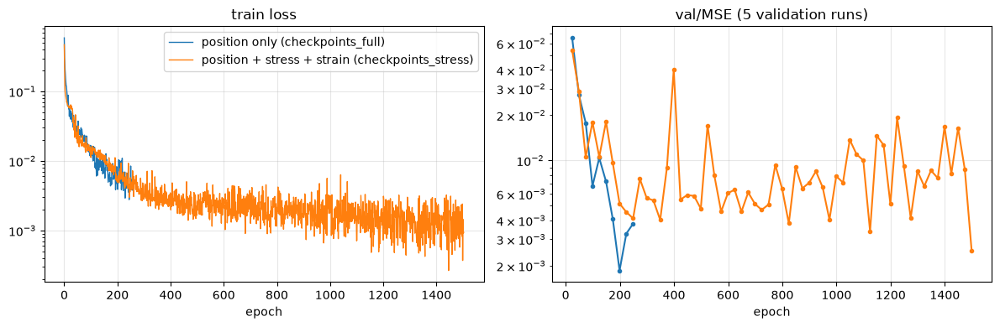

position only (checkpoints_full): last epoch 259, final val/MSE 0.00380, best val/MSE 0.00186 at epoch 200
position + stress + strain (checkpoints_stress): last epoch 1504, final val/MSE 0.00252, best val/MSE 0.00252 at epoch 1500


In [14]:
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

TB_DIR = os.path.join(PROJECT_DIR, "outputs", "tensorboard_logs")


def read_scalars(path):
    ea = EventAccumulator(path, size_guidance={"scalars": 0})
    ea.Reload()
    return {tag: pd.DataFrame([(e.step, e.value) for e in ea.Scalars(tag)], columns=["epoch", "value"])
            for tag in ea.Tags()["scalars"]}


# One event file per train.py session. The two 121-run sessions are identified by
# their start time (they match the "./checkpoints_full" / "./checkpoints_stress"
# sessions in train.log); the earlier files are the 14-run pilot.
tb_files = sorted(glob.glob(os.path.join(TB_DIR, "events.out.tfevents.*")))
for f in tb_files:
    tags = read_scalars(f)
    n = len(tags["loss"]) if "loss" in tags else 0
    print(f"{os.path.basename(f)}: {n} epochs logged")

TB_RUNS = {
    "position only (checkpoints_full)": read_scalars(tb_files[-2]),
    "position + stress + strain (checkpoints_stress)": read_scalars(tb_files[-1]),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, tags in TB_RUNS.items():
    axes[0].plot(tags["loss"].epoch, tags["loss"].value, label=label, lw=1)
    axes[1].plot(tags["val/MSE"].epoch, tags["val/MSE"].value, "o-", label=label, ms=3)
for ax, title in zip(axes, ["train loss", "val/MSE (5 validation runs)"]):
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_title(title); ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout(); plt.show()

for label, tags in TB_RUNS.items():
    v = tags["val/MSE"]
    best = v.loc[v.value.idxmin()]
    print(f"{label}: last epoch {int(tags['loss'].epoch.max()) + 1}, "
          f"final val/MSE {v.value.iloc[-1]:.5f}, best val/MSE {best.value:.5f} at epoch {int(best.epoch) + 1}")

`train.py` also logs the validation MSE of each of the 50 rollout steps (`val/timestep_<i>_MSE`). The error grows with the rollout step, because later frames have larger deformation:

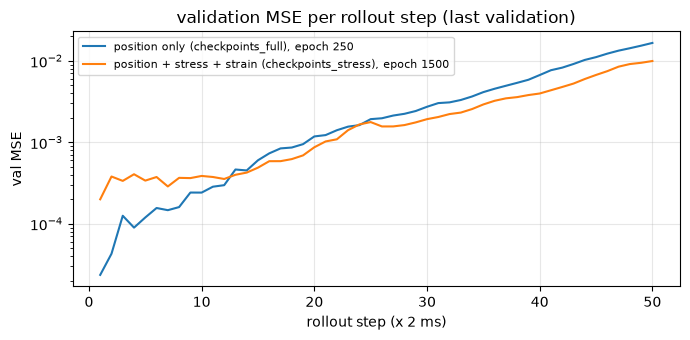

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for label, tags in TB_RUNS.items():
    last = int(tags["val/MSE"].epoch.iloc[-1])
    per_step = [tags[f"val/timestep_{i}_MSE"].set_index("epoch").value[last] for i in range(NUM_STEPS - 1)]
    ax.plot(range(1, NUM_STEPS), per_step, label=f"{label}, epoch {last + 1}")
ax.set_xlabel("rollout step (x 2 ms)"); ax.set_ylabel("val MSE"); ax.set_yscale("log")
ax.set_title("validation MSE per rollout step (last validation)"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

The two logged training runs above finished before this image logging was added, so their event files contain no images. The cell below renders the image that `train.py` now logs, with the same function (`render_true_pred_error_image`), for the epoch-1500 checkpoint on the first validation run:

val/true_pred_error_run9  (last timestep, t = 0.100 s)


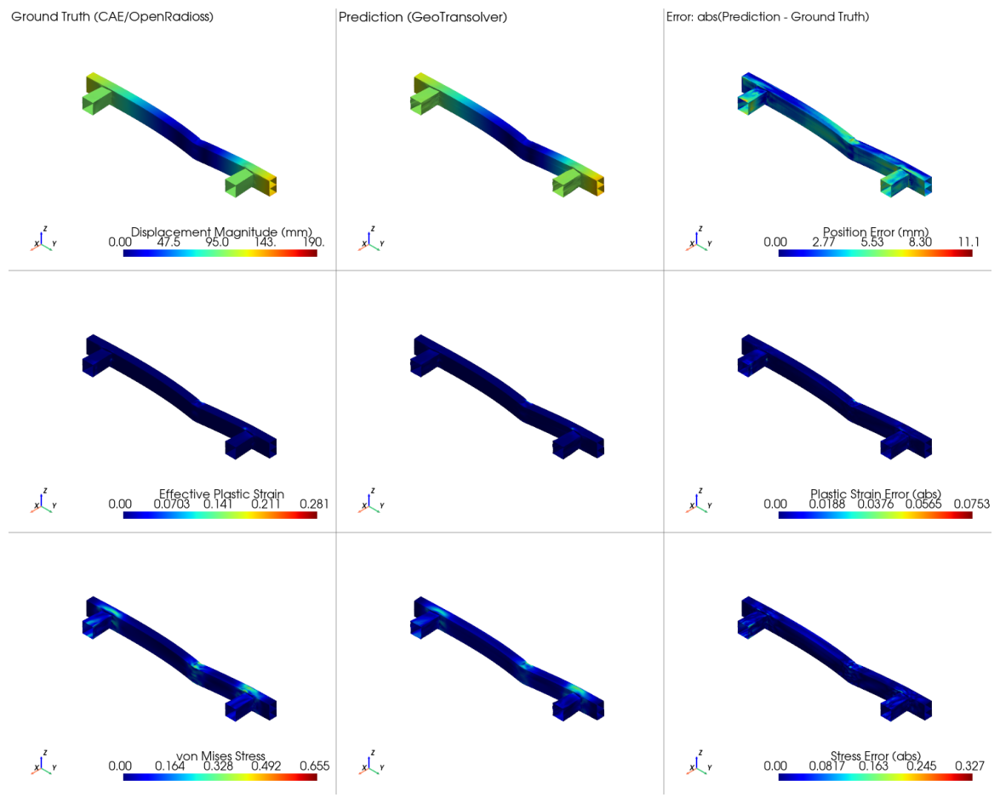

In [16]:
from make_true_pred_error_gif import render_true_pred_error_image
from vtp_reader import find_run_folders

val_ds = load_split("val", DYNAMIC_TARGETS)
val_vtp = find_run_folders(os.path.join(DATA_ROOT, "val"))[0]  # same run train.py uses
s = val_ds[0].to(DEVICE)
with torch.no_grad():
    p = model(sample=s, data_stats=data_stats)
mean = data_stats["node"]["pos_mean"].view(1, 1, -1)
std = data_stats["node"]["pos_std"].view(1, 1, -1)
c0 = s.node_features["coords"].unsqueeze(1) * std + mean
true_pos = torch.cat([c0, s.node_target[:, :, :3] * std + mean], 1).transpose(0, 1).cpu().numpy()
pred_pos = torch.cat([c0, p[:, :, :3] * std + mean], 1).transpose(0, 1).cpu().numpy()
true_sc, pred_sc = {}, {}
for i, name in enumerate(DYNAMIC_TARGETS):
    z = torch.zeros_like(p[:, :1, 3 + i])
    true_sc[name] = torch.cat([z, s.node_target[:, :, 3 + i]], 1).T.cpu().numpy()
    pred_sc[name] = torch.cat([z, p[:, :, 3 + i]], 1).T.cpu().numpy()

img = render_true_pred_error_image(true_pos[0], pyvista.read(val_vtp).faces, true_pos, pred_pos,
                                   fields=["displacement"] + DYNAMIC_TARGETS,
                                   true_scalars=true_sc, pred_scalars=pred_sc)
print(f"val/true_pred_error_{os.path.splitext(os.path.basename(val_vtp))[0]}  (last timestep, t = 0.100 s)")
plt.figure(figsize=(15, 12)); plt.imshow(img); plt.axis("off"); plt.show()

### 4.4 (Optional) Live animations during training

`post_processing/live_gif_watcher.py` watches the checkpoint folder. Each time a new checkpoint is saved, it runs inference on one test run and writes a true-versus-predicted GIF, so you can see how the model learns before training ends:

```powershell
..\..\..\.venv\Scripts\python.exe post_processing\live_gif_watcher.py `
  --ckpt_dir outputs\checkpoints --config-name bumper_openradioss_oneshot `
  --run_name run91 --poll_seconds 30
```

The watcher starts `inference.py`, which by default uses the same Hydra output folder as `train.py`. Both processes then try to write `outputs/launch.log` (`PermissionError`). The watcher sets `hydra.run.dir=./outputs_live/` and points `datapipe.stats_dir` back to `outputs/stats` with an absolute path.

### 4.5 When to stop training

With 121 samples and this model size, the validation MSE reaches a plateau within a few hundred epochs (see the plots in 4.3): position-only training converges in about 200 epochs, and with stress and strain added the plateau starts at about 600 to 900 epochs. Watch TensorBoard or the live animations and stop early. Running the full `training.epochs` (5000) is usually wasted time for a dataset this size.

## Part 5 — Inference and Visualization

Two models were trained on the same 121 runs. This part takes them **one after the other through the same steps** (export, errors, error over time, animations) and then puts them side by side:

| | 5.2 Position-only model | 5.3 Position + stress/strain model |
|---|---|---|
| Checkpoint | `outputs/checkpoints_full/GeoTransolverOneShot.0.200.mdlus` | `outputs/checkpoints_stress/GeoTransolverOneShot.0.1500.mdlus` |
| `dynamic_targets` / `out_dim` | `[]` / 150 (50 x 3) | `[effective_plastic_strain, stress_vm]` / 250 (50 x 5) |
| `inference.py` output | `outputs/{predicted,exact}_vtps_full/` | `outputs/{predicted,exact}_vtps_stress_final/` |
| Prediction VTU | `data_full/compare_vtu/predict_disponly/` | `data_full/compare_vtu/predict/` |
| Error table | `data_full/compare_vtu/metrics_disponly.csv` | `data_full/compare_vtu/metrics.csv` |
| Animations | `outputs/test_gifs_disponly/` | `outputs/test_gifs/` |

### 5.1 Run inference

```powershell
..\..\..\.venv\Scripts\python.exe inference.py --config-name=bumper_openradioss_oneshot `
  training.raw_data_dir=<...>/data_full/train `
  training.raw_data_dir_validation=<...>/data_full/val `
  training.global_features_filepath=<...>/global_features.json `
  training.num_training_samples=121 `
  training.num_validation_samples=5 `
  training.num_dataloader_workers=0 `
  training.ckpt_path=./checkpoints `
  inference.raw_data_dir_test=<...>/data_full/test
```

Run it once per model (`training.ckpt_path=./checkpoints_full` with `datapipe.dynamic_targets=[]`, and `./checkpoints_stress` with the two extra targets). The output is `outputs/predicted_vtps/rank0/<run>/frame_XXX_pred.vtp` and `outputs/exact_vtps/rank0/<run>/frame_XXX_exact.vtp`; the results used below were renamed to the folders in the table above.

**Known problem — no symlink permission on Windows.** `inference.py` links each run's VTP into a temporary folder with `os.symlink()`. Without Developer Mode or admin rights, Windows raises `OSError: [WinError 1314]`. This project's `inference.py` falls back to `shutil.copy2()`.

#### Export the predictions to VTU

`post_processing/export_pred_vtu.py` runs one checkpoint on **every** run (train, val, and test) and writes the predictions as VTU time series, with the same layout as the ground truth from Part 2.4:

```
data_full/compare_vtu/
  metrics_disponly.csv / metrics.csv     <- per-run error (%), plus split averages
  predict_disponly/ or predict/
    checkpoint.txt                       <- which checkpoint made these files
    train/ val/ test/
      runN/
        runN.pvd                         <- open in ParaView, next to openradioss/<split>/runN/runN.pvd
        vtu/runN_000.vtu ... runN_050.vtu
```

- Frame numbering and times match the ground-truth VTU files. Frame 000 is the undeformed input; the model predicts frames 001 to 050.
- Point data: `displacement`, `error_displacement` (\|pred - true\| in mm), and for the stress model also `stress_vm`, `effective_plastic_strain`, `error_stress_vm`, `error_effective_plastic_strain` (pred - true).
- The model type is read from the checkpoint, so the same script works for both. Always pass `--out_dir` and `--metrics` together with `--ckpt`; otherwise a second model writes into the first model's `predict/` folder.

The error tables give, for every run, the **relative L2 error in percent** over all nodes and all 50 predicted frames:

`error_% = 100 * ||pred - true||_2 / ||true||_2`

- `disp`: the displacement vector relative to t0 (all 3 components together).
- `effective_plastic_strain` (OpenRadioss `/ANIM/SHELL/EPSP`) and `stress_vm` (von Mises stress, `/ANIM/SHELL/VONM`): stress model only.
- The rows with `run = mean` average the per-run errors over each split (train / val / test) and over all runs.

A relative error is large when the true value is small: plastic strain is 0 on most of the beam, so its percentage error is large even when the absolute error is small.

The next cell defines the helpers that 5.2 and 5.3 both use.

In [28]:
from make_true_pred_error_gif import build_multi_gif
from IPython.display import Image, display

EXPORT_PRED = os.path.join(PROJECT_DIR, "post_processing", "export_pred_vtu.py")
test_runs = split_runs["test"]
DISP_COLS = ["disp_error_pct"]
STRESS_COLS = ["effective_plastic_strain_error_pct", "stress_vm_error_pct"]


def export_predictions(ckpt, out_dir, metrics_csv):
    # Runs that already have a .pvd are skipped; the metrics are always recomputed
    result = subprocess.run([sys.executable, EXPORT_PRED, "--ckpt", ckpt,
                             "--out_dir", out_dir, "--metrics", metrics_csv],
                            capture_output=True, text=True)
    if result.returncode != 0:
        print(result.stderr[-2000:])
        return
    print("checkpoint:", open(os.path.join(out_dir, "checkpoint.txt")).read().strip())
    for split in ["train", "val", "test"]:
        n = len(glob.glob(os.path.join(out_dir, split, "run*", "*.pvd")))
        print(f"  {os.path.basename(out_dir)}/{split:<5}: {n} runs")
    print("metrics   :", os.path.relpath(metrics_csv, PROJECT_DIR))


def show_metrics(metrics_csv, err_cols, title):
    m = pd.read_csv(metrics_csv)
    print("Average relative L2 error (%) per split (rows with run = mean):")
    display(m[m.run == "mean"].set_index("split")[err_cols].round(2))
    per_run = m[m.run != "mean"].set_index("run")
    print("Test runs:")
    display(per_run.loc[test_runs, err_cols].round(2))

    fig, ax = plt.subplots(figsize=(11, 3.5))
    x = np.arange(len(test_runs))
    w = 0.8 / len(err_cols)
    for i, col in enumerate(err_cols):
        ax.bar(x + (i - (len(err_cols) - 1) / 2) * w, per_run.loc[test_runs, col], width=w,
               label=col.replace("_error_pct", ""))
    ax.set_xticks(x); ax.set_xticklabels(test_runs)
    ax.set_ylabel("relative L2 error (%)"); ax.set_title(f"test runs: error per channel ({title})")
    ax.legend(ncol=len(err_cols), fontsize=8); ax.grid(axis="y", alpha=0.3)
    plt.tight_layout(); plt.show()
    return m


def error_curves(pred_root):
    # Mean |pred - true| (mm) per frame for every test run, from the prediction VTU files
    curves = []
    for run in test_runs:
        frames = sorted(glob.glob(os.path.join(pred_root, "test", run, "vtu", f"{run}_*.vtu")))
        curves.append([pyvista.read(f)["error_displacement"].mean() for f in frames])
    return np.array(curves)  # [runs, 51]


def plot_error_curves(curve_sets):
    fig, ax = plt.subplots(figsize=(7, 3.5))
    for label, curves in curve_sets.items():
        t_ms = np.arange(curves.shape[1]) * 2
        line, = ax.plot(t_ms, curves.mean(axis=0), label=f"{label}: mean of {len(curves)} test runs")
        ax.fill_between(t_ms, curves.min(axis=0), curves.max(axis=0), color=line.get_color(), alpha=0.15,
                        label=f"{label}: min / max over runs")
    ax.set_xlabel("time (ms)"); ax.set_ylabel("mean |pred - true| (mm)")
    ax.set_title("test runs: position error over time")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()


def make_test_gifs(exact_root, pred_root, gif_dir, fields):
    os.makedirs(gif_dir, exist_ok=True)
    for run in test_runs:
        output_gif = os.path.join(gif_dir, f"{run}_true_pred.gif")
        if os.path.exists(output_gif):
            print(f"{run}: already exists, skipping")  # delete the GIF to render it again
            continue
        build_multi_gif(os.path.join(exact_root, "rank0", run), os.path.join(pred_root, "rank0", run),
                        os.path.join(DATA_ROOT, "test", f"{run}.vtp"), output_gif, fields=fields)
    print(f"\nAnimations for all {len(test_runs)} test runs are in", gif_dir)
    display(Image(filename=os.path.join(gif_dir, "run91_true_pred.gif")))

### 5.2 Position-only model (`checkpoints_full`, epoch 200)

`dynamic_targets: []`: the model predicts only the node positions. The cell below exports its predictions for all 135 runs.

In [29]:
CKPT_FULL = os.path.join(PROJECT_DIR, "outputs", "checkpoints_full", "GeoTransolverOneShot.0.200.mdlus")
PRED_ROOT_POS = os.path.join(VTU_ROOT, "predict_disponly")
METRICS_POS = os.path.join(VTU_ROOT, "metrics_disponly.csv")
export_predictions(CKPT_FULL, PRED_ROOT_POS, METRICS_POS)

checkpoint: outputs/checkpoints_full/GeoTransolverOneShot.0.200.mdlus
  predict_disponly/train: 121 runs
  predict_disponly/val  : 5 runs
  predict_disponly/test : 9 runs
metrics   : data_full\compare_vtu\metrics_disponly.csv


Relative L2 error of the displacement, per split and per test run:

Average relative L2 error (%) per split (rows with run = mean):


,disp_error_pct
split,
train,12.70
val,8.02
test,13.60
all,12.59


Test runs:


,disp_error_pct
run,
run91,8.54
run92,15.02
run93,15.46
run94,7.31
run95,8.92
run96,11.51
run97,14.29
run98,19.08
run99,22.28


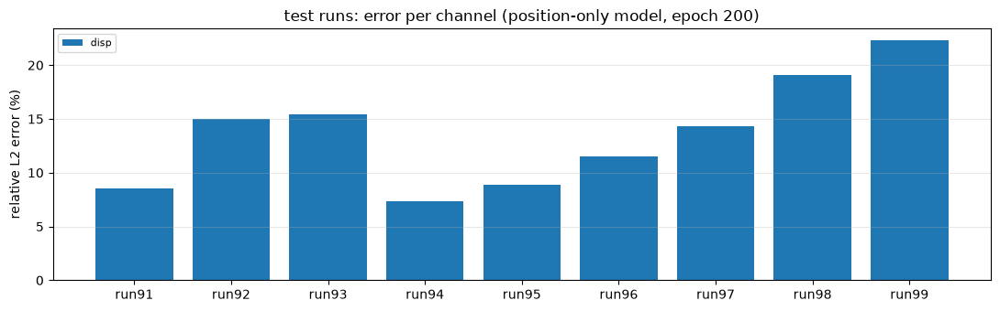

In [30]:
metrics_pos = show_metrics(METRICS_POS, DISP_COLS, "position-only model, epoch 200")

Position error over the rollout for the 9 test runs, read from the `error_displacement` field of the prediction VTU files:

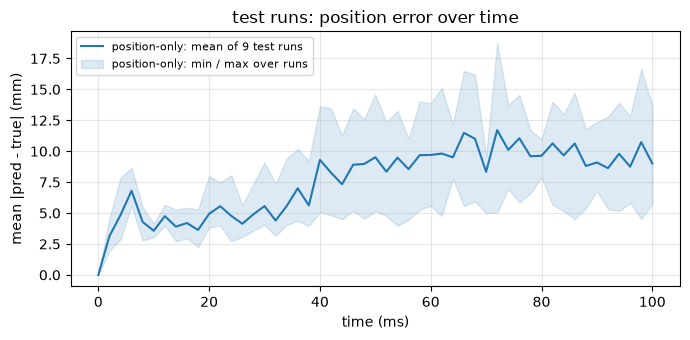

In [31]:
curves_pos = error_curves(PRED_ROOT_POS)
plot_error_curves({"position-only": curves_pos})

#### Animations

`post_processing/make_true_pred_error_gif.py` renders with PyVista: jet color scale and a fixed isometric camera (`--camera xy|xz|yz` gives axis-aligned views; the beam's long axis is Y, so `iso` is usually the clearest). One animation per test run, in `outputs/test_gifs_disponly/`. This model predicts only positions, so each image has one row:

| Ground Truth (OpenRadioss) | Prediction (GeoTransolver) | Error: abs(Prediction - Ground Truth) |
|---|---|---|
| displacement magnitude (mm) | displacement magnitude (mm) | position error \|x_pred - x_true\| (mm) |

The error column is drawn on the true deformed shape and has its own color range (0 to the largest error over all frames), so it shows where the model is wrong, not only how much.

Saved C:\code\2-cae\physicsnemo\examples\structural_mechanics\bumper_beam\outputs\test_gifs_disponly\run91_true_pred.gif (51 frames, 1 field(s): displacement)


Saved C:\code\2-cae\physicsnemo\examples\structural_mechanics\bumper_beam\outputs\test_gifs_disponly\run92_true_pred.gif (51 frames, 1 field(s): displacement)


Saved C:\code\2-cae\physicsnemo\examples\structural_mechanics\bumper_beam\outputs\test_gifs_disponly\run93_true_pred.gif (51 frames, 1 field(s): displacement)


Saved C:\code\2-cae\physicsnemo\examples\structural_mechanics\bumper_beam\outputs\test_gifs_disponly\run94_true_pred.gif (51 frames, 1 field(s): displacement)


Saved C:\code\2-cae\physicsnemo\examples\structural_mechanics\bumper_beam\outputs\test_gifs_disponly\run95_true_pred.gif (51 frames, 1 field(s): displacement)


Saved C:\code\2-cae\physicsnemo\examples\structural_mechanics\bumper_beam\outputs\test_gifs_disponly\run96_true_pred.gif (51 frames, 1 field(s): displacement)


Saved C:\code\2-cae\physicsnemo\examples\structural_mechanics\bumper_beam\outputs\test_gifs_disponly\run97_true_pred.gif (51 frames, 1 field(s): displacement)


Saved C:\code\2-cae\physicsnemo\examples\structural_mechanics\bumper_beam\outputs\test_gifs_disponly\run98_true_pred.gif (51 frames, 1 field(s): displacement)


Saved C:\code\2-cae\physicsnemo\examples\structural_mechanics\bumper_beam\outputs\test_gifs_disponly\run99_true_pred.gif (51 frames, 1 field(s): displacement)

Animations for all 9 test runs are in C:\code\2-cae\physicsnemo\examples\structural_mechanics\bumper_beam\outputs\test_gifs_disponly


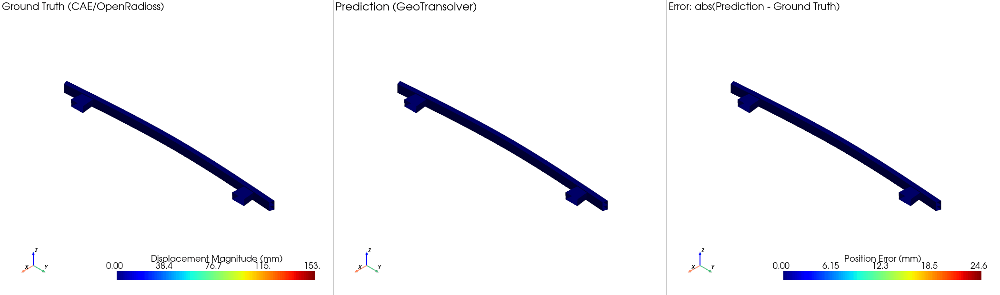

In [32]:
make_test_gifs(os.path.join(PROJECT_DIR, "outputs", "exact_vtps_full"),
               os.path.join(PROJECT_DIR, "outputs", "predicted_vtps_full"),
               os.path.join(PROJECT_DIR, "outputs", "test_gifs_disponly"),
               fields=["displacement"])

### 5.3 Position + stress/strain model (`checkpoints_stress`, epoch 1500)

`dynamic_targets: [effective_plastic_strain, stress_vm]`: the same steps as 5.2, with two more output channels.

In [33]:
PRED_ROOT = os.path.join(VTU_ROOT, "predict")
METRICS_STRESS = os.path.join(VTU_ROOT, "metrics.csv")
export_predictions(CKPT_STRESS, PRED_ROOT, METRICS_STRESS)

checkpoint: outputs/checkpoints_stress/GeoTransolverOneShot.0.1500.mdlus
  predict/train: 121 runs
  predict/val  : 5 runs
  predict/test : 9 runs
metrics   : data_full\compare_vtu\metrics.csv


Relative L2 error of the displacement, plastic strain, and von Mises stress, per split and per test run:

Average relative L2 error (%) per split (rows with run = mean):


,disp_error_pct,effective_plastic_strain_error_pct,stress_vm_error_pct
split,,,
train,3.74,35.79,16.44
val,8.52,66.46,30.52
test,42.91,135.07,59.25
all,6.53,43.54,19.81


Test runs:


,disp_error_pct,effective_plastic_strain_error_pct,stress_vm_error_pct
run,,,
run91,27.61,133.98,67.42
run92,35.13,120.31,64.82
run93,44.19,150.83,69.11
run94,18.16,94.94,44.39
run95,23.24,85.99,42.95
run96,27.25,106.47,46.24
run97,46.75,172.33,64.71
run98,86.13,148.03,65.40
run99,77.75,202.74,68.16


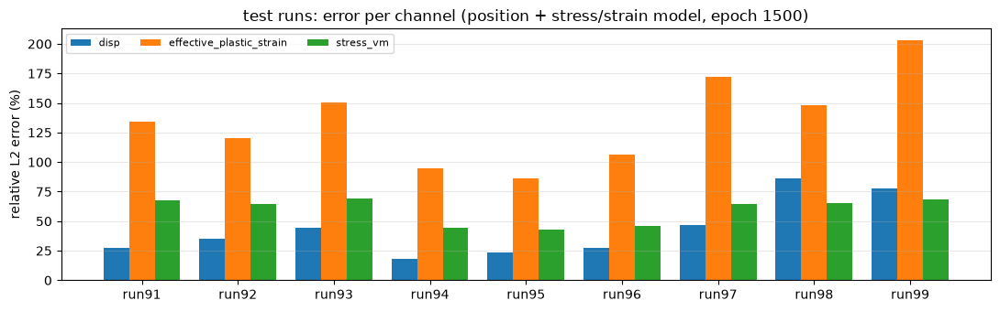

In [34]:
metrics_stress = show_metrics(METRICS_STRESS, DISP_COLS + STRESS_COLS, "position + stress/strain model, epoch 1500")

Position error over the rollout for the 9 test runs:

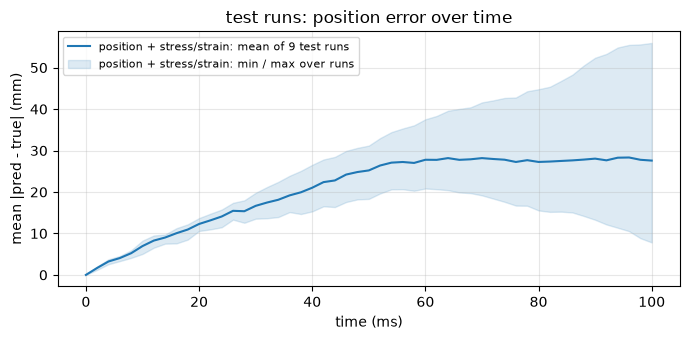

In [35]:
curves_stress = error_curves(PRED_ROOT)
plot_error_curves({"position + stress/strain": curves_stress})

#### Animations

Same renderer, in `outputs/test_gifs/`. Each image now has 3 rows and 3 columns:

| | Ground Truth (OpenRadioss) | Prediction (GeoTransolver) | Error: abs(Prediction - Ground Truth) |
|---|---|---|---|
| Displacement magnitude (mm) | | | position error \|x_pred - x_true\| (mm) |
| von Mises stress | | | abs(stress error) |
| Effective plastic strain | | | abs(strain error) |

Plastic strain is above 0 only in a few local areas, so its ground truth and prediction look almost all blue; the error column shows where the strain prediction differs.

run91: already exists, skipping
run92: already exists, skipping
run93: already exists, skipping
run94: already exists, skipping
run95: already exists, skipping
run96: already exists, skipping
run97: already exists, skipping
run98: already exists, skipping
run99: already exists, skipping

Animations for all 9 test runs are in C:\code\2-cae\physicsnemo\examples\structural_mechanics\bumper_beam\outputs\test_gifs


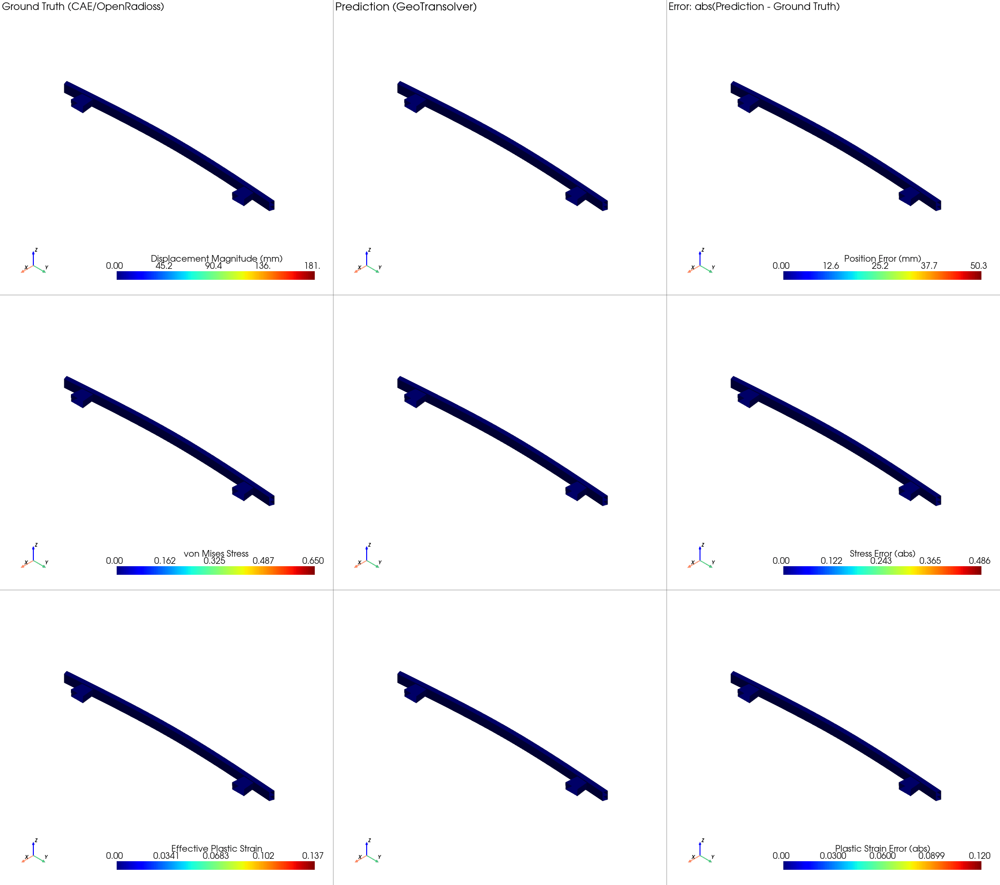

In [36]:
make_test_gifs(os.path.join(PROJECT_DIR, "outputs", "exact_vtps_stress_final"),
               os.path.join(PROJECT_DIR, "outputs", "predicted_vtps_stress_final"),
               os.path.join(PROJECT_DIR, "outputs", "test_gifs"),
               fields=["displacement", "stress_vm", "effective_plastic_strain"])

`post_processing/per_field_mse.py` computes the MSE of each field separately from the `difference` / `diff_<field>` arrays in the exact VTP files. This shows how each physical quantity converges, which the single combined MSE in the training log does not:

In [37]:
for run in ["run91", "run95"]:
    exact_dir = os.path.join(PROJECT_DIR, "outputs", "exact_vtps_stress_final", "rank0", run)
    result = subprocess.run([sys.executable, os.path.join(PROJECT_DIR, "post_processing", "per_field_mse.py"),
                             "--exact_dir", exact_dir], capture_output=True, text=True)
    print(f"--- {run} ---")
    print(result.stdout.strip() or result.stderr[-1500:])

--- run91 ---
frames: 50
position MSE (mean over all timesteps): 137.821243
effective_plastic_strain MSE (mean over all timesteps): 0.000026  (last-frame: 0.000058)
stress_vm MSE (mean over all timesteps): 0.009906  (last-frame: 0.013305)


--- run95 ---
frames: 50
position MSE (mean over all timesteps): 169.745056
effective_plastic_strain MSE (mean over all timesteps): 0.000011  (last-frame: 0.000017)
stress_vm MSE (mean over all timesteps): 0.004303  (last-frame: 0.002951)


### 5.4 The two models side by side

The same three views as in 5.2 and 5.3, now with both models together: the displacement error per split, per test run, and over time.

disp error (%), mean per split:


,position-only (epoch 200),position + stress/strain (epoch 1500)
split,,
train,12.70,3.74
val,8.02,8.52
test,13.60,42.91


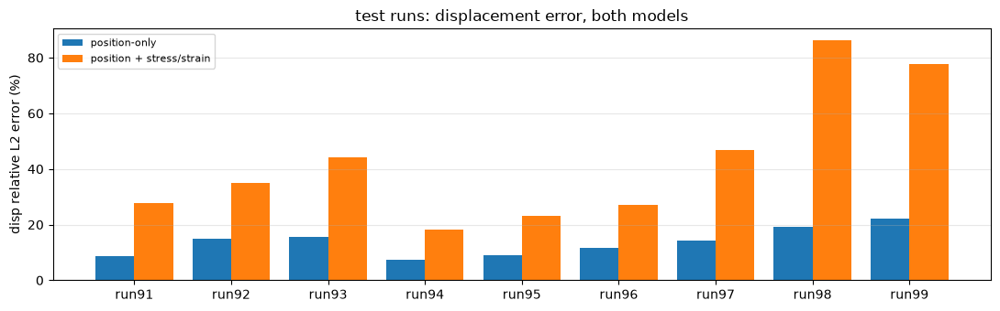

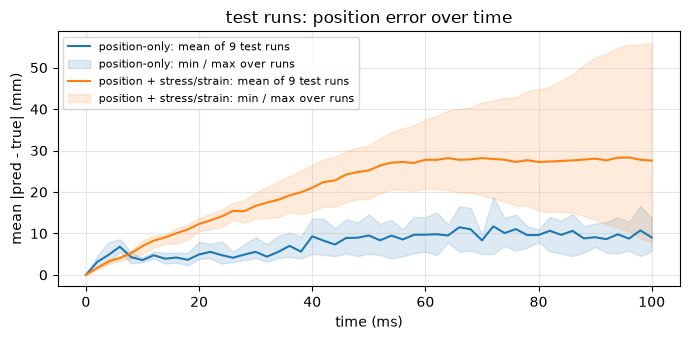

In [38]:
mean_pos = metrics_pos[metrics_pos.run == "mean"].set_index("split")
mean_str = metrics_stress[metrics_stress.run == "mean"].set_index("split")
print("disp error (%), mean per split:")
display(pd.DataFrame({"position-only (epoch 200)": mean_pos["disp_error_pct"],
                      "position + stress/strain (epoch 1500)": mean_str["disp_error_pct"]})
        .loc[["train", "val", "test"]].round(2))

pr_pos = metrics_pos[metrics_pos.run != "mean"].set_index("run").loc[test_runs, "disp_error_pct"]
pr_str = metrics_stress[metrics_stress.run != "mean"].set_index("run").loc[test_runs, "disp_error_pct"]
fig, ax = plt.subplots(figsize=(11, 3.5))
x = np.arange(len(test_runs))
ax.bar(x - 0.2, pr_pos, width=0.4, label="position-only")
ax.bar(x + 0.2, pr_str, width=0.4, label="position + stress/strain")
ax.set_xticks(x); ax.set_xticklabels(test_runs)
ax.set_ylabel("disp relative L2 error (%)"); ax.set_title("test runs: displacement error, both models")
ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

plot_error_curves({"position-only": curves_pos, "position + stress/strain": curves_stress})

What the three views show:

- **Train vs test.** The stress model fits the training runs much better (disp 3.7% vs 12.7%) but is three times worse on the test runs (42.9% vs 13.6%): it **overfits**. The position-only model has about the same error on train, val and test.
- **Every test run.** The position-only model is better on all 9 test runs. Both models are worst on run98 and run99 (thickness 1.3, wall y = 120 / 240), but the stress model's error there is 78 to 86% against 19 to 22%.
- **Over time.** Both start at the same error. After about 10 ms the stress model's error keeps growing, to a mean of 28 mm at 100 ms (worst run 56 mm); the position-only model stays at about 9 to 10 mm.

So the extra stress / strain targets cost displacement accuracy on new cases. Part 6 explains why (one MSE loss over channels with different scales), and Part 7 adds the per-node R² for both models.

## Part 6 — (Advanced, Not Fully Solved) Predicting Stress and Plastic Strain

### 6.1 Where the data comes from

Curator (`PNM-25.11-Compatible`) reads only node coordinates, displacement, thickness, and connectivity from d3plot. It **does not** read stress or strain. The engine deck writes `/ANIM/SHELL/VONM` and `/ANIM/SHELL/EPSP`, but `vortex_radioss` drops these two fields during the ANIM-to-d3plot conversion (they become all-zero `element_shell_unknown_variables`).

The good news: **the two fields are still in the `.vtk` files made by `anim_to_vtk`**, as cell data `2DELEM_Von_Mises` and `2DELEM_Plastic_Strain`. The cell below opens the last real frame of run1.

In [22]:
vtk_last = pyvista.read(os.path.join(SIM_DIR, "run1", "Bumper_Beam_AP_meshedA051.vtk"))
print(f"Bumper_Beam_AP_meshedA051.vtk: {vtk_last.n_cells} cells (shells + beams + reference geometry)")
print("cell data :", list(vtk_last.cell_data.keys()))
print("point data:", list(vtk_last.point_data.keys()))
print("max 2DELEM_Von_Mises (GPa):", float(np.max(vtk_last["2DELEM_Von_Mises"])))
print("max 2DELEM_Plastic_Strain  :", float(np.max(vtk_last["2DELEM_Plastic_Strain"])))

Bumper_Beam_AP_meshedA051.vtk: 13889 cells (shells + beams + reference geometry)
cell data : ['ELEMENT_ID', 'PART_ID', 'EROSION_STATUS', '2DELEM_Plastic_Strain', '2DELEM_Von_Mises']
point data: ['NODE_ID']
max 2DELEM_Von_Mises (GPa): 0.6131460070610046
max 2DELEM_Plastic_Strain  : 0.3250260055065155


### 6.2 How the fields are added to the VTP

`vtp_reader.py` already reads cell data named `cell_stress_vm_t{time}` / `cell_effective_plastic_strain_t{time}`. It converts them to node data with `cell_data_to_point_data()` and removes the `cell_` prefix. So the only step is to map `2DELEM_Von_Mises` / `2DELEM_Plastic_Strain` from the `.vtk` files to the Curator VTP mesh by `ELEMENT_ID` and write them back as new cell data. **The reader and datapipe code do not change.**

The `.vtk` cell order is different from the d3plot element order, and the `.vtk` file mixes shells and beams:
1. Read `element_shell_ids` (the authoritative shell order) with `lasso.dyna.D3plot`.
2. Read the `.vtk` with PyVista and keep the cells with `celltype in [TRIANGLE, QUAD]` and an `ELEMENT_ID` in the shell ID set. This gives a clean one-to-one match (13626 shell IDs -> exactly 13626 cells, no duplicates, nothing missing).
3. Reorder the values to the `element_shell_ids` order and save them as new cell data in the Curator VTP.

```python
# Core logic; the full version is dataset_generation/templates/_inject_stress_strain.py
is_2d = np.isin(ctypes, [VTK_TRIANGLE, VTK_QUAD])
cand = np.where(is_2d & np.isin(elem_id, shell_id_set))[0]
id_to_cell = {elem_id[ci]: ci for ci in cand}   # first match wins; verified to have no duplicates
ordered_idx = [id_to_cell[sid] for sid in shell_ids]
vtp.cell_data[f"cell_stress_vm_t{t:.3f}"] = vonm[ordered_idx]
vtp.cell_data[f"cell_effective_plastic_strain_t{t:.3f}"] = eps[ordered_idx]
```

> Before you use this mapping, check that the shell element count is the same in the d3plot and in the Curator VTP for every run (in this dataset all 135 runs match). If Curator's `WallNodeFilter` removes shells for some geometry, the "reorder by original order" assumption breaks and a per-element remap is needed.

One run (51 timesteps) takes 4 to 5 seconds; all 135 runs take about **10 minutes**. The cell below checks the result in the real `data_full` files and compares one frame with the source `.vtk`.

In [23]:
n_ok = 0
for split, runs in split_runs.items():
    for run in runs:
        v = pyvista.read(os.path.join(DATA_ROOT, split, f"{run}.vtp"))
        n_s = sum(k.startswith("cell_stress_vm_t") for k in v.cell_data.keys())
        n_e = sum(k.startswith("cell_effective_plastic_strain_t") for k in v.cell_data.keys())
        n_ok += (n_s == NUM_STEPS and n_e == NUM_STEPS)
print(f"VTP files with all {NUM_STEPS} stress and strain frames: {n_ok} / {sum(map(len, split_runs.values()))}")

# Same frame, two sources: the max value must be identical after the ELEMENT_ID mapping
shell_mask = np.isin(vtk_last.celltypes, [pyvista.CellType.TRIANGLE, pyvista.CellType.QUAD])
print(f"run1 t=0.100 max stress_vm: VTP {vtp['cell_stress_vm_t0.100'].max():.6f}  vs  .vtk shells {vtk_last['2DELEM_Von_Mises'][shell_mask].max():.6f}")

VTP files with all 51 stress and strain frames: 135 / 135
run1 t=0.100 max stress_vm: VTP 0.613146  vs  .vtk shells 0.613146


### 6.3 Config for the two extra targets

```yaml
datapipe:
  dynamic_targets:
    - effective_plastic_strain
    - stress_vm

model:
  out_dim: 250   # (51-1) * 5 = 50 * (3 position + 1 strain + 1 stress)
```

### 6.4 Known problem: position accuracy gets worse with longer training

Same 121 training runs, same model and hyperparameters; the only change is the two extra targets. The cell below runs **every saved checkpoint** of both real training runs on the 9 test runs and computes the MSE of each field in physical units. This reproduces the table in Part 6.4 of the guide.

,model,epoch,position (mm^2),stress_vm,effective_plastic_strain
0,stress,100,368.056873,0.009037,0.000089
1,stress,200,165.965988,0.008564,0.000064
2,stress,300,227.363567,0.008175,0.000056
3,stress,400,697.748517,0.008636,0.000053
4,stress,500,262.620480,0.009017,0.000048
5,stress,600,306.653973,0.008761,0.000039
6,stress,700,186.915246,0.008304,0.000034
7,stress,800,208.340261,0.009738,0.000033
8,stress,900,365.593294,0.009189,0.000031
9,stress,1000,357.920952,0.008795,0.000027


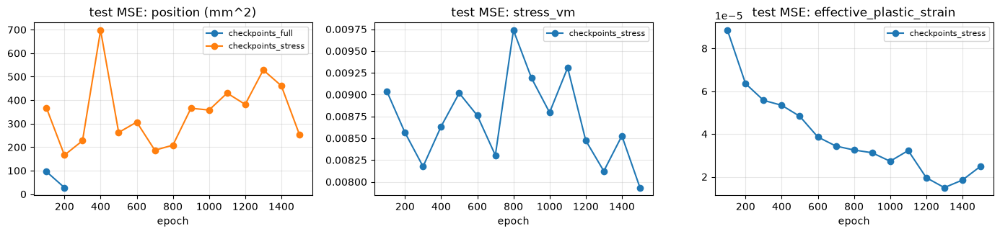

In [24]:
def ckpt_epoch(path):
    return int(re.search(r"\.(\d+)\.mdlus$", path).group(1))


test_ds_pos = load_split("test", [])  # position-only targets for the checkpoints_full model
pos_mean = data_stats["node"]["pos_mean"].view(1, 1, -1)
pos_std = data_stats["node"]["pos_std"].view(1, 1, -1)

sweep = []
for variant, ds in [("stress", test_ds), ("full", test_ds_pos)]:
    ckpts = sorted(glob.glob(os.path.join(PROJECT_DIR, "outputs", f"checkpoints_{variant}", "*.mdlus")), key=ckpt_epoch)
    for ckpt in ckpts:
        m, _ = load_trained_model(ckpt)
        se = {"position (mm^2)": [], "stress_vm": [], "effective_plastic_strain": []}
        with torch.no_grad():
            for i in range(len(ds)):
                s = ds[i].to(DEVICE)
                p = m(sample=s, data_stats=data_stats)
                y = s.node_target
                pos_err = (p[:, :, :3] - y[:, :, :3]) * pos_std  # back to mm
                se["position (mm^2)"].append((pos_err ** 2).mean().item())
                if p.shape[-1] == 5:
                    se["effective_plastic_strain"].append(((p[:, :, 3] - y[:, :, 3]) ** 2).mean().item())
                    se["stress_vm"].append(((p[:, :, 4] - y[:, :, 4]) ** 2).mean().item())
        sweep.append({"model": variant, "epoch": ckpt_epoch(ckpt),
                      **{k: (np.mean(v) if v else np.nan) for k, v in se.items()}})
        del m
        torch.cuda.empty_cache()

sweep = pd.DataFrame(sweep)
display(sweep.round(6))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["position (mm^2)", "stress_vm", "effective_plastic_strain"]):
    for variant, g in sweep.groupby("model"):
        if g[col].notna().any():
            ax.plot(g.epoch, g[col], "o-", label=f"checkpoints_{variant}")
    ax.set_title(f"test MSE: {col}"); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

What the guide reports for this run, and what to look for in the table and plots above:

- **Plastic strain** converges smoothly and stays at a low error after about 700 epochs.
- **Stress** oscillates in a narrow band from start to end. It does not really converge, but it does not get worse either.
- **Position** is not stable: it gets **worse and noisier the longer training runs**. The position-only model (`checkpoints_full`) converges smoothly on the same data.

The likely cause: `train.py` uses one `torch.nn.MSELoss()` over all 5 channels. Position is z-score normalized, but stress and strain keep their raw physical scale (0 to 1 range), and there is no per-channel weight. The gradients of the three quantities interfere with each other. **This is not a case of too little training**: training for 1500+ epochs does not fix it. The fix is a change to the loss, for example a separate MSE per channel with weights, or normalizing each channel by its standard deviation.

If you only need an accurate position surrogate, keep `dynamic_targets: []` (the Part 4 default). It is the only setup that has been verified to converge fully.

## Part 7 — Results: Position-Only Model vs Position + Stress/Strain Model

Same 121 training runs, same GeoTransolver architecture; the only difference is whether stress and plastic strain are also predicted.

| | Position-only model | Position + stress/strain model |
|---|---|---|
| Checkpoint | `outputs/checkpoints_full/GeoTransolverOneShot.0.200.mdlus` | `outputs/checkpoints_stress/GeoTransolverOneShot.0.1500.mdlus` |
| `dynamic_targets` / `out_dim` | `[]` / 150 (50 x 3) | `[effective_plastic_strain, stress_vm]` / 250 (50 x 5) |
| Training epochs | 200 | 1500 |
| Prediction VTU | `data_full/compare_vtu/predict_disponly/` | `data_full/compare_vtu/predict/` |
| Error table | `data_full/compare_vtu/metrics_disponly.csv` | `data_full/compare_vtu/metrics.csv` |

### 7.1 Error (relative L2 %, lower is better)

In [ ]:
import pandas as pd

CMP = os.path.join(PROJECT_DIR, "data_full", "compare_vtu")
m_pos = pd.read_csv(os.path.join(CMP, "metrics_disponly.csv"))
m_str = pd.read_csv(os.path.join(CMP, "metrics.csv"))
mean_pos = m_pos[m_pos.run == "mean"].set_index("split")
mean_str = m_str[m_str.run == "mean"].set_index("split")
table = pd.DataFrame({
    "position-only: disp": mean_pos["disp_error_pct"],
    "stress model: disp": mean_str["disp_error_pct"],
    "stress model: eps": mean_str["effective_plastic_strain_error_pct"],
    "stress model: von Mises": mean_str["stress_vm_error_pct"],
}).loc[["train", "val", "test"]]
display(table.round(2))

,position-only: disp,stress model: disp,stress model: eps,stress model: von Mises
split,,,,
train,12.70,3.74,35.79,16.44
val,8.02,8.52,66.46,30.52
test,13.60,42.91,135.07,59.25


The stress model has only 3.7% displacement error on train but 42.9% on test: it **overfits**. The position-only model has about the same error on train and test (12.7% / 13.6%) and is three times better on test.

### 7.2 R² (test, per node, true vs predicted)

`post_processing/plot_r2_scatter.py`. All frames: 9 test runs x 50 predicted frames x 13,675 nodes. Final state only (`--last_frame`): frame 050, t = 100 ms, the evaluation used by final-state surrogates (Part 8).

| | R² (test, 50 frames) | R² (test, final state only) |
|---|---|---|
| Position-only model: displacement \|u\| | **0.979** | **0.980** |
| Stress model: displacement \|u\| | 0.608 | 0.641 |
| Stress model: plastic strain eps | −0.857 | −1.348 |
| Stress model: von Mises stress | 0.143 | −0.121 |

For the position-only model both are about the same, so its R² does not come from the small early deformations. Final state: displacement RMSE 10.41 mm (vector), relative L2 11.4%.

**Position-only model:**

![R² scatter, position-only model, test set](../figures/r2_scatter_test_disponly.png)

Final state only:

![R² scatter, position-only model, test set, final state](../figures/r2_scatter_test_disponly_last.png)

**Position + stress/strain model**: displacement lies almost entirely above the diagonal (systematic overprediction); most true plastic strain values are 0 but the predictions scatter around 0; von Mises stress scatters widely, even with physically impossible negative values.

![R² scatter, stress + strain model, test set](../figures/r2_scatter_test_stress.png)

> **Do not compute R² on absolute coordinates.** The beam is 2 m long, so even a prediction with no deformation at all gets R² ≈ 0.9999 on absolute positions.

### 7.3 True / predicted / error animations (test `run91`)

Columns: **Ground Truth | Prediction | Error = abs(Prediction − Ground Truth)**.

Position-only model:

![run91, position-only model](../figures/run91_disponly_true_pred_error.gif)

Position + stress/strain model:

![run91, stress + strain model](../figures/run91_stress_true_pred_error.gif)

### 7.4 Conclusions

- **For a displacement surrogate, use the position-only model** (`dynamic_targets: []`): test displacement R² 0.979, relative L2 13.6%.
- **Adding stress/strain targets hurts the displacement** (test R² 0.979 → 0.608), and the stress/strain predictions themselves have almost no skill on test (R² 0.14 / −0.86). Cause: one `MSELoss` over channels with different scales (Part 6).
- The percentage errors of `uy`, `uz` and plastic strain are large mainly because their true values are small; use absolute errors (mm) for these.

## Part 8 — Related Work: Also a Bumper, but Not the Same Case

R. Gulakala, M. Stoffel, *Global Graph Surrogates and Neural Graph Elements for Computational Mechanics*, PAMM 26(4), e70233, 2026 (open access, [doi:10.1002/pamm.70233](https://doi.org/10.1002/pamm.70233)). This paper also builds a graph-network surrogate (DI-GNN) for an aluminium automotive bumper impact, but the model, data and evaluation differ from this notebook: **the numbers are not directly comparable**.

### 8.1 Case comparison

| | Paper | This notebook |
|---|---|---|
| Model source | own Abaqus model (with crash boxes) | OpenRadioss example `Bumper_Beam_AP_meshed` |
| Solver | Abaqus/Explicit | OpenRadioss |
| Material | aluminium, Johnson–Cook (A = 520 MPa, B = 477 MPa, E = 70 GPa) | elasto-plastic shell material of the example |
| Loading | one end fully fixed, prescribed velocity at the other end (axial impact) | cylindrical rigid wall impact |
| DOE | cross-section A–E x length 1100/1200/1300 mm x depth 150/200/250 mm x thickness 1.0–3.0 mm, full factorial, **225 runs**; **the cross-section topology changes** | geometry scale x impact velocity x thickness scale x wall y position, **135 runs**; same topology, **the loading changes** |
| Split | 180 / 45 (train / validation only; the paper's "test set of 45" is this 20%) | 121 / 5 / 9 (train / val / test) |
| Prediction | displacement, stress, strain at the **final state only** | the **whole time history** (50 frames); displacement, or displacement + plastic strain + von Mises |
| Model | DI-GNN: 1 FEMAT + 7 GATv2 layers, 8 heads, hidden 128, ≈1.2M parameters, 500 epochs | GeoTransolver one-shot |
| Loss | MSE + displacement-gradient loss + linear-elastic constitutive residual, two-phase (physics terms switched on after the data loss converges) | MSE only |

### 8.2 Results

Paper (45 runs, final-state displacement):

| Model | RMSE (mm) | R² |
|---|---|---|
| DI-GNN | 12.75 | 0.846 |
| EA-GNN | 14.05 | 0.785 |
| MeshGraphNet | 15.25 | 0.702 |

Position-only GeoTransolver of this notebook (9 test runs, all nodes):

| Evaluated on | RMSE (mm) | R² | Relative L2 |
|---|---|---|---|
| 50 frames | — | 0.979 | 13.6% |
| **Final state only** (same basis as the paper) | **10.41** | **0.980** | 11.4% |

The numbers here are higher, but **that does not mean the model is better**: the paper's DOE changes the cross-section topology (harder to extrapolate), the deformation magnitudes differ (the paper gives no range), and the paper has no separate test set.

### 8.3 Notes on the paper

- Eq. (3) puts a "stress state σ_i" in the node input; if that is the simulated result, the answer is in the input.
- The constitutive loss uses the linear-elastic C while the material is Johnson–Cook plastic; the authors call it a corrective guide, not a physically consistent constraint.
- The captions of Figs. 5–7 give a length of 1500 mm, which is not one of the levels in Table 1 (1100–1300 mm).

### 8.4 Ideas worth trying

- **Geometry-aware normalization (LMGS)**: positions and displacements divided by L_ref (mesh size), stress by E. This DOE has geometry scaling, so it is worth a try.
- **Two-phase loss**: train on the data loss first, then add the other terms; a candidate fix for the Part 6 problem (displacement R² 0.979 → 0.608 when stress/strain are added).

Both were tried in the DI-GNN reproduction of Part 9; on this data's test set they did not help.

## Part 9 — Three Models: GeoTransolver vs MeshGraphNet vs DI-GNN (Re-implementation)

Same data, same task, three models:

- **GeoTransolver**: the model of this notebook (transformer with a global context).
- **MeshGraphNet**: the graph network built into PhysicsNeMo, also a baseline in the paper.
- **DI-GNN**: re-implemented from Section 3 of the Part 8 paper.

### 9.1 Common setup

- Data: 135 runs, 121 / 5 / 9 (train / val / test), as in Part 4.
- Task: **displacement only** (`dynamic_targets: []`), one-shot, all 50 frames at once.
- Training: 500 epochs with a full cosine learning-rate cycle, evaluated at the last epoch. The Part 7 position-only GeoTransolver was trained for 200 epochs on a schedule set for 5000, so its learning rate barely decayed; it was retrained here (the old one stays in `outputs/checkpoints_full/`).

| | GeoTransolver | MeshGraphNet | DI-GNN (re-impl.) |
|---|---|---|---|
| Config | `bumper_openradioss_oneshot` + `datapipe.dynamic_targets=[] model.out_dim=150` | `bumper_mgn_oneshot` | `bumper_dignn_oneshot` |
| Class (`rollout.py`) | `GeoTransolverOneShot` | `MeshGraphNetOneShot` | `DIGNNOneShot` (new) |
| Data representation | point cloud | graph (mesh edges) | graph (mesh edges) |
| Parameters | 7.16M | 2.35M | 0.32M |
| Optimizer / lr | Muon / 1e-4 | Muon / 1e-4 | Adam / 1e-3 → 1e-5 (as in the paper) |
| Time per epoch (RTX 4060 Ti) | 20 s | 23 s | 7 s |
| Training folder | `outputs_geotransolver/` | `outputs_mgn/` | `outputs_dignn/` |

Commands (run in the project folder):

```powershell
$PY = "..\..\..\.venv\Scripts\python.exe"
& $PY train.py --config-name=bumper_dignn_oneshot
& $PY train.py --config-name=bumper_mgn_oneshot
& $PY train.py --config-name=bumper_openradioss_oneshot hydra.run.dir=./outputs_geotransolver `
  'training.raw_data_dir=${hydra:runtime.cwd}/data_full/vtk/train' 'training.raw_data_dir_validation=${hydra:runtime.cwd}/data_full/vtk/val' `
  'training.global_features_filepath=${hydra:runtime.cwd}/dataset_generation/global_features.json' `
  'inference.raw_data_dir_test=${hydra:runtime.cwd}/data_full/vtk/test' training.num_training_samples=121 training.num_validation_samples=5 `
  training.epochs=500 training.validation_freq=25 training.save_checkpoint_freq=50 'datapipe.dynamic_targets=[]' model.out_dim=150
# evaluate + export VTU (predict_<tag>/, metrics_<tag>.csv, summary_<tag>.json)
& $PY post_processing\export_pred_vtu.py --run_dir outputs_dignn --tag dignn      # likewise outputs_mgn / outputs_geotransolver
& $PY post_processing\plot_model_comparison.py
```

> **On an 8 GB GPU, train one model at a time.** Three at once fill the GPU memory, Windows starts paging it to system memory, and an epoch goes from 20 s to over 100 s.

### 9.2 How DI-GNN was re-implemented

`rollout.DIGNNOneShot` follows Section 3 of the paper, built on PyG `GATv2Conv`. Where the paper is unclear or does not fit this data:

| Paper | This implementation |
|---|---|
| node features h = [x, u_bc, σ, m] | x after LMGS normalization; u_bc = impact velocity and wall y position; m = thickness scale. σ (initial stress) is 0 in this data and left out |
| FEMAT (Eq. 5–6): GATv2 + W_x·Δx + W_m·Δm + W_d·(d_i⊙d_j) | layer 1 is `GATv2Conv(edge_dim=8)` with edge features [standardized dx, dy, dz, \|d\|, Δm, d_i⊙d_j]; one linear map on the concatenated edge features equals the three separate W terms. d_i = absolute shell normal estimated by PCA of the neighbour positions (the sign of a normal is arbitrary) |
| 1 FEMAT + 7 GATv2, 8 heads, hidden 128, LeakyReLU 0.2 | same; plus residual + LayerNorm per layer (not specified in the paper) and gradient checkpointing (otherwise it does not fit in 8 GB) |
| material conditioning M before the decoder | the material and loading vector is concatenated to the latent features before the decoder |
| LMGS (Eq. 7–9): L_ref = max node distance | L_ref = bounding-box diagonal (an upper bound of the max distance, no all-pairs computation); the network outputs u / L_ref |
| gradient loss (Eq. 11), λ₁ = 0.1, switched on after the data loss converges | displacement gradient as an edge finite difference, error divided by the edge length (normalized by the mean edge length); switched on at epoch 250 |
| constitutive loss (Eq. 13–14), λ₂ = 0.01 | **not used**: it needs predicted stress and plastic strain, which a position-only model does not have |
| ≈1.2M parameters | 0.32M: that is what hidden 128 with 8 layers gives; the paper is not self-consistent here |
| final state only | all 50 frames at once, like the other two models |

### 9.3 Results

The cell below reads `data_full/compare_vtu/summary_<tag>.json` (written by `export_pred_vtu.py --run_dir`). Relative L2 is computed per run and then averaged; R² and RMSE pool all nodes.

In [ ]:
import json

MODELS = [("geotransolver", "GeoTransolver"), ("mgn", "MeshGraphNet"), ("dignn", "DI-GNN (re-impl.)")]
rows = []
for tag, name in MODELS:
    s = json.load(open(os.path.join(CMP, f"summary_{tag}.json")))["splits"]
    for split in ["train", "val", "test"]:
        e = s[split]
        rows.append({"split": split, "model": name,
                     "rel L2 % (50 frames)": e["disp_rel_l2_pct"]["mean"],
                     "median %": e["disp_rel_l2_pct"]["median"],
                     "R2 (50 frames)": e["disp_r2"],
                     "R2 (final state)": e["disp_r2_final"],
                     "RMSE mm (final state)": e["disp_rmse_mm_final"]})
results = pd.DataFrame(rows).set_index(["split", "model"])
display(results.round(3))

,,rel L2 % (50 frames),median %,R2 (50 frames),R2 (final state),RMSE mm (final state)
split,model,,,,,
train,GeoTransolver,3.766,2.972,1.000,1.000,5.588
val,GeoTransolver,5.695,6.232,0.996,0.988,15.688
test,GeoTransolver,14.513,13.388,0.970,0.967,12.777
train,MeshGraphNet,3.837,3.311,0.999,0.999,6.917
val,MeshGraphNet,6.845,6.479,0.991,0.970,19.874
test,MeshGraphNet,20.391,19.482,0.912,0.901,19.524
train,DI-GNN (re-impl.),5.753,4.442,0.999,0.998,9.903
val,DI-GNN (re-impl.),7.455,7.706,0.992,0.989,16.858
test,DI-GNN (re-impl.),30.981,20.953,0.847,0.863,30.224


![Displacement error per model, test set](../figures/model_comparison_error.png)

![R² per model, test set](../figures/model_comparison_r2.png)

![Final-frame R² scatter per model, test set](../figures/model_comparison_r2_final.png)

The final-state relative L2 mean (orange bars) is pulled up by the small-deformation runs run97–99: their maximum displacement is only about 30 mm, so a 30 mm miss is a 100% error. For DI-GNN the final-state mean is 92% but the median only 20%; R² and RMSE are the fairer comparison.

### 9.4 Why the gap: the test set is an extrapolation

The cell below lists the test runs with their parameters and the error of each model.

In [ ]:
gf = json.load(open(os.path.join(PROJECT_DIR, "dataset_generation", "global_features.json")))
PARAMS = ["geo_scale_y", "geo_scale_z", "velocity_x", "thickness_scale", "rwall_origin_y"]
per_run = {}
for tag, name in MODELS:
    m = pd.read_csv(os.path.join(CMP, f"metrics_{tag}.csv"))
    per_run[name] = m[(m.run != "mean") & (m.split == "test")].set_index("run")["disp_error_pct"]
test_table = pd.DataFrame({p: {r: gf[r][p] for r in per_run["GeoTransolver"].index} for p in PARAMS})
test_table = test_table.join(pd.DataFrame(per_run).add_suffix(" disp %"))
display(test_table.round(2))

train_runs = [f[:-4] for f in os.listdir(os.path.join(PROJECT_DIR, "data_full", "vtk", "train"))]
combo = pd.Series([(gf[r]["geo_scale_y"], gf[r]["velocity_x"]) for r in train_runs]).value_counts()
print("training runs with geo_scale_y = 2.0, per impact velocity:")
print({v: int(combo.get((2.0, v), 0)) for v in (-7.0, -5.0, -3.0)})

,geo_scale_y,geo_scale_z,velocity_x,thickness_scale,rwall_origin_y,GeoTransolver disp %,MeshGraphNet disp %,DI-GNN (re-impl.) disp %
run91,2.0,1.0,-3.0,1.0,0.0,7.54,20.52,19.77
run92,2.0,1.0,-3.0,1.0,120.0,13.39,17.59,20.95
run93,2.0,1.0,-3.0,1.0,240.0,15.21,16.32,23.32
run94,2.0,1.0,-3.0,0.7,0.0,4.08,15.15,13.44
run95,2.0,1.0,-3.0,0.7,120.0,4.71,19.48,14.46
run96,2.0,1.0,-3.0,0.7,240.0,7.66,11.75,19.20
run97,2.0,1.0,-3.0,1.3,0.0,16.76,25.57,66.87
run98,2.0,1.0,-3.0,1.3,120.0,28.19,30.77,52.68
run99,2.0,1.0,-3.0,1.3,240.0,33.08,26.35,48.14


training runs with geo_scale_y = 2.0, per impact velocity:
{-7.0: 9, -5.0: 5, -3.0: 0}


All 9 test runs (run91–99) are **wide geometry (geo_scale_y = 2) + low speed (−3 mm/ms)**. This combination never appears in training: the wide geometry was only trained with −7 and −5 mm/ms, and −3 mm/ms only with the other geometries. So the test set asks for an unseen parameter combination, while val (wide geometry + −5 mm/ms) is almost inside the training distribution.

- **Inside the distribution (train / val) all three models are good.** DI-GNN reaches the same val R² as GeoTransolver with 1/20 of the parameters, consistent with the paper's "high predictive accuracy within the training distribution" (the paper's test set is its validation set).
- **For the extrapolation, GeoTransolver with its global context is the most robust.** Both graph networks rely on local message passing (MGN 15 steps, DI-GNN 8 layers) that cannot carry the response of a 13,675-node beam across the whole structure.
- **DI-GNN is worst on the thick-plate runs run97–99 (48–67% error)**; the other two models are also worst there, but less so.
- **LMGS normalization may hurt here**: the wide geometry has a larger L_ref, so the network output u / L_ref must be scaled up while the low speed makes the displacement smaller; both effects have to be inferred for an unseen combination.
- **The two-phase gradient loss shows no clear effect**: after epoch 250 the val MSE keeps falling (0.0022 → 0.0016), but the learning rate is falling at the same time.

**Conclusion**: to predict unseen parameter combinations, GeoTransolver is the best choice, MeshGraphNet second. DI-GNN suits the paper's use, interpolation inside a known distribution: small, fast to train (1 h vs 2.8 h for GeoTransolver), with in-distribution accuracy close to GeoTransolver.

> Each model was trained once (no repeated seeds); the test set has only 9 runs of one extrapolation combination. The large gaps (GeoTransolver > MGN > DI-GNN) are reliable; differences of a few percent are not. DI-GNN was re-implemented from the paper's text, not from the authors' code, and the differences listed in 9.2 may all affect the result.

## Summary: Where Everything Is

```
bumper_beam/
├── dataset_generation/
│   ├── templates/                    # starter + engine deck, _inject_stress_strain.py   (Part 2.1, 6.2)
│   ├── generate_dataset.py           # DOE generator                                    (Part 2.2)
│   ├── run_simulations.py            # batch OpenRadioss runs                           (Part 2.3)
│   ├── dataset/run1..run135/         # raw simulation output (26 GB)
│   └── global_features.json          # per-run global parameters                        (Part 2.5)
├── conf/bumper_openradioss_oneshot.yaml                                                 (Part 4.1)
├── conf/bumper_{mgn,dignn}_oneshot.yaml, conf/model/dignn_one_shot.yaml                 (Part 9)
├── data_full/
│   ├── vtk/train/ val/ test/         # Curator VTP files, 121 / 5 / 9                   (Part 3)
│   └── compare_vtu/
│       ├── openradioss/<split>/runN/ # ground truth VTU time series (runN.pvd + vtu/)   (Part 2.4)
│       ├── predict/<split>/runN/     # stress model prediction VTU                      (Part 5.3)
│       ├── metrics.csv               # stress model: per-run error (%) + split averages (Part 5.3)
│       ├── predict_disponly/, metrics_disponly.csv  # position-only model             (Part 5.2)
│       ├── predict_{geotransolver,mgn,dignn}/, metrics_<tag>.csv, summary_<tag>.json  (Part 9)
│       └── r2_scatter_per_node*.png  # per-node true vs predicted + R²                 (Part 7.2)
├── outputs_{geotransolver,mgn,dignn}/ # training folders of the three-model comparison  (Part 9)
├── outputs/
│   ├── checkpoints_full/             # position-only model
│   ├── checkpoints_stress/           # position + stress + strain model
│   ├── tensorboard_logs/             # loss, validation curves, validation images       (Part 4.3)
│   ├── predicted_vtps_*/ exact_vtps_*/                                                  (Part 5.1)
│   ├── test_gifs_disponly/           # true / predicted / error, position-only model    (Part 5.2)
│   └── test_gifs/                    # true / predicted / error, stress model           (Part 5.3)
├── post_processing/
│   ├── export_vtu.py                 # ground truth -> VTU
│   ├── export_pred_vtu.py            # checkpoint -> prediction VTU (--run_dir: any model)
│   ├── plot_r2_scatter.py            # per-node R² (--last_frame: final state only)    (Part 7.2)
│   ├── plot_model_comparison.py      # three-model comparison figures                  (Part 9)
│   ├── make_true_pred_error_gif.py, per_field_mse.py, live_gif_watcher.py
└── BUMPER_BEAM_REPRODUCTION.md       # full reproduction guide
```

For the architecture derivation (why the context is `[8,128,128]` and not `O(N)`, how GALE differs from FLARE, and so on), see [bumper_beam_geotransolver_notes.md](../notes/bumper_beam_geotransolver_notes.md).

### The whole pipeline in one picture

![Bumper beam pipeline: from CAE data to a crash surrogate](../figures/pipeline_overview.png)

Read from top to bottom. The upper band runs in WSL (OpenRadioss and Curator ship only Linux tools), the lower band in native Windows (CUDA training). Steps 1 to 8 on the left are the main chain; the boxes on the right are side branches: the global features that go straight to training, the `.vtk` path for stress and plastic strain (Part 6), the ParaView files, and the other models (Part 9). Every box names its script, its output, and the section of this notebook. The figure is drawn by `figures/make_pipeline_diagram.py`.
